## **Check video formats**

In [ ]:
import os
from collections import Counter

# Шлях до твоєї головної папки з епізодами
SOURCE_ROOT = r"E:\bachelor_data\episods"

def analyze_video_formats(root_path):
    print(f"Scanning directory: {root_path} ...\n")
    
    if not os.path.exists(root_path):
        print("Error: The specified path does not exist. Please check the drive letter and folder name.")
        return

    extension_counter = Counter()
    total_files = 0
    total_folders = 0

    # Проходимося по всіх папках та підпапках
    for dirpath, dirnames, filenames in os.walk(root_path):
        total_folders += 1
        for file in filenames:
            total_files += 1
            # Витягуємо розширення
            ext = os.path.splitext(file)[1].lower()
            
            if ext == "":
                ext = "no_extension"
                
            extension_counter[ext] += 1

    # Виводимо результати
    print("-" * 30)
    print("STATISTICS RESULTS:")
    print("-" * 30)
    print(f"Total folders checked: {total_folders}")
    print(f"Total files found: {total_files}\n")
    
    print("Format distribution:")
    if not extension_counter:
        print("The folder is empty.")
    else:
        # Сортуємо від найчастіших до найрідкісніших
        for ext, count in extension_counter.most_common():
            print(f"  {ext}: {count} items")

if __name__ == "__main__":
    analyze_video_formats(SOURCE_ROOT)

Scanning directory: E:\bachelor_data\bachelor_data_episods ...

------------------------------
STATISTICS RESULTS:
------------------------------
Total folders checked: 118
Total files found: 610

Format distribution:
  .mp4: 550 items
  .mov: 32 items
  .m4v: 28 items


In [6]:
import os
import cv2
import numpy as np
import pandas as pd
import plotly.express as px
from tqdm import tqdm

SOURCE_ROOT = r"E:\bachelor_data\dataset"

total_duration_sec = 0
valid_videos_count = 0
durations_data = [] # Додано масив для зберігання даних про кожне відео

# 1. Збираємо всі шляхи до файлів
all_videos = []
for root, dirs, files in os.walk(SOURCE_ROOT):
    for file in files:
        if file.lower().endswith(('.mp4', '.mov', '.m4v')):
            all_videos.append(os.path.join(root, file))

print(f"Знайдено файлів для аналізу: {len(all_videos)}")

# 2. Швидко зчитуємо метадані кожного відео
for video_path in tqdm(all_videos, desc="Аналіз тривалості"):
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        continue
        
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    
    if fps > 0 and total_frames > 0:
        duration = total_frames / fps
        total_duration_sec += duration
        valid_videos_count += 1
        
        # Зберігаємо ім'я файлу та його тривалість для гістограми
        durations_data.append({
            'filename': os.path.basename(video_path),
            'duration_sec': duration
        })
        
    cap.release()

print("\n📊 ДЕТАЛІЗАЦІЯ РОЗПОДІЛУ (Консоль):")
# Витягуємо тільки числа (тривалості)
durations = [d['duration_sec'] for d in durations_data]

# Розраховуємо 50 кошиків (як у Plotly)
counts, bin_edges = np.histogram(durations, bins=50)

# Виводимо тільки ті діапазони, де є хоча б 1 відео
for i in range(len(counts)):
    if counts[i] > 0:
        print(f"Від {bin_edges[i]:.1f} до {bin_edges[i+1]:.1f} сек: {counts[i]} відео")

# 3. Виводимо зрозумілу статистику
if valid_videos_count > 0:
    avg_duration = total_duration_sec / valid_videos_count
    
    hours = int(total_duration_sec // 3600)
    minutes = int((total_duration_sec % 3600) // 60)
    
    print(f"\n📊 СТАТИСТИКА ДАТАСЕТУ:")
    print(f"Успішно прочитано: {valid_videos_count} відео")
    print(f"Сумарний час: {hours} годин {minutes} хвилин ({total_duration_sec:.1f} сек)")
    print(f"Середня тривалість одного відео: {avg_duration:.1f} сек")
    
    # 4. Побудова інтерактивної гістограми
    print("\n📈 Генерація інтерактивної гістограми...")
    df = pd.DataFrame(durations_data)
    
    fig = px.histogram(
        df, 
        x="duration_sec", 
        nbins=50, # Кількість стовпчиків (можна змінити для більшої деталізації)
        title="Розподіл тривалості відео у датасеті",
        labels={"duration_sec": "Тривалість (секунди)"},
        hover_data=["filename"], # Показувати назву файлу при наведенні курсору
        color_discrete_sequence=['#3366CC']
    )
    
    # Налаштування вигляду
    fig.update_layout(
        yaxis_title="Кількість відео",
        bargap=0.05, # Візуальні відступи між стовпчиками
        template="plotly_white"
    )
    
    # Відкриває графік (у браузері, якщо це локальний скрипт, або прямо в клітинці Jupyter/Kaggle)
    fig.show()

else:
    print("Не знайдено валідних відео.")

Знайдено файлів для аналізу: 594


Аналіз тривалості: 100%|██████████| 594/594 [00:05<00:00, 101.80it/s]


📊 ДЕТАЛІЗАЦІЯ РОЗПОДІЛУ (Консоль):
Від 0.2 до 0.6 сек: 2 відео
Від 0.6 до 1.1 сек: 28 відео
Від 1.1 до 1.5 сек: 67 відео
Від 1.5 до 1.9 сек: 70 відео
Від 1.9 до 2.4 сек: 70 відео
Від 2.4 до 2.8 сек: 72 відео
Від 2.8 до 3.3 сек: 42 відео
Від 3.3 до 3.7 сек: 34 відео
Від 3.7 до 4.1 сек: 34 відео
Від 4.1 до 4.6 сек: 17 відео
Від 4.6 до 5.0 сек: 9 відео
Від 5.0 до 5.4 сек: 19 відео
Від 5.4 до 5.9 сек: 16 відео
Від 5.9 до 6.3 сек: 16 відео
Від 6.3 до 6.7 сек: 13 відео
Від 6.7 до 7.2 сек: 15 відео
Від 7.2 до 7.6 сек: 7 відео
Від 7.6 до 8.1 сек: 10 відео
Від 8.1 до 8.5 сек: 5 відео
Від 8.5 до 8.9 сек: 5 відео
Від 8.9 до 9.4 сек: 4 відео
Від 9.4 до 9.8 сек: 2 відео
Від 9.8 до 10.2 сек: 5 відео
Від 10.2 до 10.7 сек: 3 відео
Від 10.7 до 11.1 сек: 2 відео
Від 11.1 до 11.5 сек: 4 відео
Від 11.5 до 12.0 сек: 3 відео
Від 12.0 до 12.4 сек: 2 відео
Від 12.4 до 12.9 сек: 1 відео
Від 12.9 до 13.3 сек: 1 відео
Від 13.3 до 13.7 сек: 5 відео
Від 14.2 до 14.6 сек: 1 відео
Від 14.6 до 15.0 сек: 2 відео
Від 

In [5]:
import os
import cv2

SOURCE_ROOT = r"E:\bachelor_data\dataset"

print("Пошук найдовших відео...\n")
videos_data = []

# Збираємо всі відео та їхню тривалість
for root, dirs, files in os.walk(SOURCE_ROOT):
    for file in files:
        if file.lower().endswith(('.mp4', '.mov', '.m4v')):
            filepath = os.path.join(root, file)
            cap = cv2.VideoCapture(filepath)
            if cap.isOpened():
                fps = cap.get(cv2.CAP_PROP_FPS)
                total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                if fps > 0:
                    videos_data.append({
                        'file': file,
                        'path': filepath,
                        'duration': total_frames / fps
                    })
            cap.release()

# Сортуємо за тривалістю (від найдовшого до найкоротшого)
videos_data.sort(key=lambda x: x['duration'], reverse=True)

# Виводимо ТОП-5 найдовших
print("🛑 ТОП-5 найдовших відео у датасеті:")
for i, v in enumerate(videos_data[:5]):
    print(f"{i+1}. {v['file']} — {v['duration']:.1f} сек")
    print(f"   Шлях: {v['path']}\n")

Пошук найдовших відео...

🛑 ТОП-5 найдовших відео у датасеті:
1. delta_rgb_sky_104.mp4 — 57.8 сек
   Шлях: E:\bachelor_data\dataset\delta_rgb_sky_104.mp4

2. wing_rgb_sky_428.mp4 — 22.0 сек
   Шлях: E:\bachelor_data\dataset\wing_rgb_sky_428.mp4

3. delta_rgb_field_068.mp4 — 21.1 сек
   Шлях: E:\bachelor_data\dataset\delta_rgb_field_068.mp4

4. delta_rgb_field_069.mp4 — 20.1 сек
   Шлях: E:\bachelor_data\dataset\delta_rgb_field_069.mp4

5. wing_rgb_field_284.mp4 — 18.4 сек
   Шлях: E:\bachelor_data\dataset\wing_rgb_field_284.mp4



In [ ]:
import numpy as np

# ... (попередній код зчитування відео) ...

# === НОВИЙ БЛОК: Вивід у консоль ===

# ===================================

# 4. Побудова інтерактивної гістограми
# print("\n📈 Генерація інтерактивної гістограми...")
# fig = px.histogram( ... )


📊 ДЕТАЛІЗАЦІЯ РОЗПОДІЛУ (Консоль):
Від 0.2 до 1.4 сек: 75 відео
Від 1.4 до 2.5 сек: 183 відео
Від 2.5 до 3.7 сек: 124 відео
Від 3.7 до 4.8 сек: 59 відео
Від 4.8 до 6.0 сек: 41 відео
Від 6.0 до 7.1 сек: 39 відео
Від 7.1 до 8.3 сек: 21 відео
Від 8.3 до 9.4 сек: 13 відео
Від 9.4 до 10.6 сек: 10 відео
Від 10.6 до 11.7 сек: 7 відео
Від 11.7 до 12.9 сек: 5 відео
Від 12.9 до 14.0 сек: 6 відео
Від 14.0 до 15.2 сек: 2 відео
Від 15.2 до 16.3 сек: 2 відео
Від 17.5 до 18.6 сек: 3 відео
Від 19.8 до 20.9 сек: 1 відео
Від 20.9 до 22.1 сек: 2 відео
Від 56.6 до 57.8 сек: 1 відео


In [3]:
import cv2
from tqdm import tqdm

SOURCE_ROOT = r"E:\bachelor_data\episods"

total_duration_sec = 0
valid_videos_count = 0

# 1. Збираємо всі шляхи до файлів
all_videos = []
for root, dirs, files in os.walk(SOURCE_ROOT):
    for file in files:
        if file.lower().endswith(('.mp4', '.mov', '.m4v')):
            all_videos.append(os.path.join(root, file))

print(f"Знайдено файлів для аналізу: {len(all_videos)}")

# 2. Швидко зчитуємо метадані кожного відео
for video_path in tqdm(all_videos, desc="Аналіз тривалості"):
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        continue
        
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    
    if fps > 0 and total_frames > 0:
        duration = total_frames / fps
        total_duration_sec += duration
        valid_videos_count += 1
        
    cap.release()

# 3. Виводимо зрозумілу статистику
if valid_videos_count > 0:
    avg_duration = total_duration_sec / valid_videos_count
    
    hours = int(total_duration_sec // 3600)
    minutes = int((total_duration_sec % 3600) // 60)
    
    print(f"\n📊 СТАТИСТИКА ДАТАСЕТУ:")
    print(f"Успішно прочитано: {valid_videos_count} відео")
    print(f"Сумарний час: {hours} годин {minutes} хвилин ({total_duration_sec:.1f} сек)")
    print(f"Середня тривалість одного відео: {avg_duration:.1f} сек")
else:
    print("Не знайдено валідних відео.")

Знайдено файлів для аналізу: 610


Аналіз тривалості: 100%|██████████| 610/610 [00:11<00:00, 53.73it/s]


📊 СТАТИСТИКА ДАТАСЕТУ:
Успішно прочитано: 610 відео
Сумарний час: 0 годин 40 хвилин (2403.9 сек)
Середня тривалість одного відео: 3.9 сек


In [ ]:
import os

# Шлях до твоєї папки з перевіреними відео
DIR = r"E:\bachelor_data\dataset"

# Твої СУВОРІ класи з промпту
VALID_TARGETS = ["delta", "cross", "wing", "no_drone"]
VALID_CAMERAS = ["rgb", "thermal"]

# Я додав "field_pattern" про всяк випадок, якщо він залишився від попередньої версії скрипта
VALID_BGS = ["sky", "uniform", "field", "forest", "urban", "horizon"]

errors = []
valid_count = 0

print("Починаємо перевірку на одруківки...\n" + "="*50)

for filename in os.listdir(DIR):
    if not filename.lower().endswith(('.mp4', '.mov', '.m4v')):
        continue

    # 1. Шукаємо ціль (target)
    found_target = None
    for t in VALID_TARGETS:
        if filename.startswith(t + "_"):
            found_target = t
            break
            
    if not found_target:
        errors.append((filename, "Помилка в класі ЦІЛІ (або його немає)"))
        continue

    # Відкушуємо знайдену ціль від назви
    remainder1 = filename[len(found_target) + 1:] 

    # 2. Шукаємо камеру (camera)
    found_camera = None
    for c in VALID_CAMERAS:
        if remainder1.startswith(c + "_"):
            found_camera = c
            break
            
    if not found_camera:
        errors.append((filename, "Помилка в класі КАМЕРИ"))
        continue

    # Відкушуємо знайдену камеру
    remainder2 = remainder1[len(found_camera) + 1:]

    # 3. Шукаємо фон (background)
    found_bg = None
    for b in VALID_BGS:
        if remainder2.startswith(b + "_"):
            found_bg = b
            break
            
    if not found_bg:
        errors.append((filename, "Помилка в класі ФОНУ"))
        continue

    # Якщо ми дійшли сюди, файл названо ідеально
    valid_count += 1

# --- ВИВЕДЕННЯ РЕЗУЛЬТАТІВ ---
if errors:
    print(f"🚨 ЗНАЙДЕНО ПОМИЛОК/ОДРУКІВОК: {len(errors)}")
    print("-" * 50)
    for bad_file, reason in errors:
        print(f"[!] {reason} -> {bad_file}")
else:
    print(f"✅ Усі {valid_count} файлів названо правильно.")
print("="*50)

Починаємо перевірку на одруківки...
✅ Усі 597 файлів названо правильно.


In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування для Jupyter та красивих графіків
%matplotlib inline
sns.set_theme(style="whitegrid")

DATASET_DIR = r"E:\bachelor_data\dataset"

# 1. Збираємо дані з назв файлів
data = []
video_extensions = ('.mp4', '.mov', '.m4v')

for file in os.listdir(DATASET_DIR):
    if file.lower().endswith(video_extensions):
        name_without_ext = os.path.splitext(file)[0]
        parts = name_without_ext.split('_')
        
        # Обробка no_drone
        if len(parts) >= 2 and parts[0] == 'no' and parts[1] == 'drone':
            shape = 'no_drone'
            # Достатньо 4 частин, щоб дістати камеру і фон
            if len(parts) >= 4:
                camera = parts[2]
                bg = parts[3]
            else:
                continue 
        else:
            # Обробка wing, delta, cross
            if len(parts) >= 4:
                shape = parts[0]
                camera = parts[1]
                bg = parts[2]
            else:
                continue
                
        combined_class = f"{shape}_{camera}_{bg}"
        
        data.append({
            'Файл': file,
            'Форма (Shape)': shape,
            'Камера (Camera)': camera,
            'Фон (Background)': bg,
            'Комбінований клас': combined_class
        })

df = pd.DataFrame(data)

# 2. Виводимо текстову статистику
print("📊 БАЗОВА СТАТИСТИКА ДАТАСЕТУ")
print("="*40)
print(f"Загальна кількість відео: {len(df)}")
print("-" * 40)
print("Розподіл за ФОРМОЮ дрона:")
print(df['Форма (Shape)'].value_counts().to_string())
print("-" * 40)
print("Розподіл за типом КАМЕРИ:")
print(df['Камера (Camera)'].value_counts().to_string())
print("-" * 40)
print("Розподіл за ФОНОМ:")
print(df['Фон (Background)'].value_counts().to_string())
print("="*40)

📊 БАЗОВА СТАТИСТИКА ДАТАСЕТУ
Загальна кількість відео: 597
----------------------------------------
Розподіл за ФОРМОЮ дрона:
Форма (Shape)
wing        358
delta       196
cross        40
no_drone      3
----------------------------------------
Розподіл за типом КАМЕРИ:
Камера (Camera)
rgb        319
thermal    278
----------------------------------------
Розподіл за ФОНОМ:
Фон (Background)
sky        284
field      171
horizon    117
complex     25


In [12]:
import os

# ================= НАЛАШТУВАННЯ =================
DATASET_DIR = r"E:\bachelor_data\dataset"  # Твоя папка з відео
TARGET_BGS = {'urban', 'forest', 'uniform'} # Фони, які треба замінити
NEW_BG = 'complex'                          # На що міняємо
VIDEO_EXT = ('.mp4', '.mov', '.mkv', '.m4v')
# ================================================

def rename_backgrounds():
    renamed_count = 0
    skipped_count = 0
    
    print(f"🔍 Починаємо перевірку папки: {DATASET_DIR}\n")
    
    for filename in os.listdir(DATASET_DIR):
        if not filename.lower().endswith(VIDEO_EXT):
            continue
            
        name_no_ext, ext = os.path.splitext(filename)
        parts = name_no_ext.split('_')
        
        bg_index = -1
        
        # Логіка пошуку індексу фону (враховуючи наш no_drone)
        if len(parts) >= 4 and parts[0] == 'no' and parts[1] == 'drone':
            bg_index = 3  # Для no_drone_rgb_sky_123 фон лежить під індексом 3
        elif len(parts) >= 3 and parts[0] != 'no':
            bg_index = 2  # Для wing_rgb_sky_123 фон лежить під індексом 2
            
        # Якщо знайшли фон і він у нашому списку на заміну
        if bg_index != -1 and bg_index < len(parts):
            current_bg = parts[bg_index]
            
            if current_bg in TARGET_BGS:
                # Замінюємо тільки це конкретне слово
                parts[bg_index] = NEW_BG
                
                # Склеюємо назад (нумерація в кінці parts залишається як була)
                new_name_no_ext = "_".join(parts)
                new_filename = f"{new_name_no_ext}{ext}"
                
                old_path = os.path.join(DATASET_DIR, filename)
                new_path = os.path.join(DATASET_DIR, new_filename)
                
                # Фізично перейменовуємо файл
                os.rename(old_path, new_path)
                print(f"✅ Перейменовано: {filename}  -->  {new_filename}")
                renamed_count += 1
            else:
                skipped_count += 1
                
    print("\n" + "="*40)
    print(f"🎉 Готово! Успішно перейменовано {renamed_count} файлів.")
    print(f"⏭️ Пропущено (не потребували змін): {skipped_count} файлів.")
    print("="*40)

if __name__ == "__main__":
    rename_backgrounds()

🔍 Починаємо перевірку папки: E:\bachelor_data\dataset

✅ Перейменовано: cross_rgb_forest_006.mp4  -->  cross_rgb_complex_006.mp4
✅ Перейменовано: cross_rgb_forest_007.mp4  -->  cross_rgb_complex_007.mp4
✅ Перейменовано: delta_rgb_forest_075.m4v  -->  delta_rgb_complex_075.m4v
✅ Перейменовано: delta_rgb_uniform_106.mp4  -->  delta_rgb_complex_106.mp4
✅ Перейменовано: delta_rgb_uniform_107.mp4  -->  delta_rgb_complex_107.mp4
✅ Перейменовано: delta_rgb_uniform_108.mp4  -->  delta_rgb_complex_108.mp4
✅ Перейменовано: delta_rgb_uniform_109.mp4  -->  delta_rgb_complex_109.mp4
✅ Перейменовано: delta_rgb_urban_110.m4v  -->  delta_rgb_complex_110.m4v
✅ Перейменовано: delta_rgb_urban_111.mp4  -->  delta_rgb_complex_111.mp4
✅ Перейменовано: delta_rgb_urban_112.mp4  -->  delta_rgb_complex_112.mp4
✅ Перейменовано: delta_rgb_urban_113.mp4  -->  delta_rgb_complex_113.mp4
✅ Перейменовано: delta_thermal_forest_168.m4v  -->  delta_thermal_complex_168.m4v
✅ Перейменовано: delta_thermal_forest_169.m4v  --

In [22]:
# Налаштування для Jupyter та красивих графіків
%matplotlib inline
sns.set_theme(style="whitegrid")

DATASET_DIR = r"E:\bachelor_data\dataset"

# 1. Збираємо дані з назв файлів
data = []
video_extensions = ('.mp4', '.mov', '.m4v')

for file in os.listdir(DATASET_DIR):
    if file.lower().endswith(video_extensions):
        name_without_ext = os.path.splitext(file)[0]
        parts = name_without_ext.split('_')
        
        # Обробка no_drone
        if len(parts) >= 2 and parts[0] == 'no' and parts[1] == 'drone':
            shape = 'no_drone'
            # Достатньо 4 частин, щоб дістати камеру і фон
            if len(parts) >= 4:
                camera = parts[2]
                bg = parts[3]
            else:
                continue 
        else:
            # Обробка wing, delta, cross
            if len(parts) >= 4:
                shape = parts[0]
                camera = parts[1]
                bg = parts[2]
            else:
                continue
                
        combined_class = f"{shape}_{camera}_{bg}"
        
        data.append({
            'Файл': file,
            'Форма (Shape)': shape,
            'Камера (Camera)': camera,
            'Фон (Background)': bg,
            'Комбінований клас': combined_class
        })

df = pd.DataFrame(data)

# 2. Виводимо текстову статистику
print("📊 БАЗОВА СТАТИСТИКА ДАТАСЕТУ")
print("="*40)
print(f"Загальна кількість відео: {len(df)}")
print("-" * 40)
print("Розподіл за ФОРМОЮ дрона:")
print(df['Форма (Shape)'].value_counts().to_string())
print("-" * 40)
print("Розподіл за типом КАМЕРИ:")
print(df['Камера (Camera)'].value_counts().to_string())
print("-" * 40)
print("Розподіл за ФОНОМ:")
print(df['Фон (Background)'].value_counts().to_string())
print("="*40)

📊 БАЗОВА СТАТИСТИКА ДАТАСЕТУ
Загальна кількість відео: 594
----------------------------------------
Розподіл за ФОРМОЮ дрона:
Форма (Shape)
wing     358
delta    196
cross     40
----------------------------------------
Розподіл за типом КАМЕРИ:
Камера (Camera)
rgb        316
thermal    278
----------------------------------------
Розподіл за ФОНОМ:
Фон (Background)
sky        283
field      169
horizon    117
complex     25


C:\Users\anykn\AppData\Local\Temp\ipykernel_2740\3308546456.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Форма (Shape)', order=df['Форма (Shape)'].value_counts().index, ax=ax1, palette="Blues_r")
C:\Users\anykn\AppData\Local\Temp\ipykernel_2740\3308546456.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Камера (Camera)', order=df['Камера (Camera)'].value_counts().index, ax=ax2, palette="Oranges_r")
C:\Users\anykn\AppData\Local\Temp\ipykernel_2740\3308546456.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.c

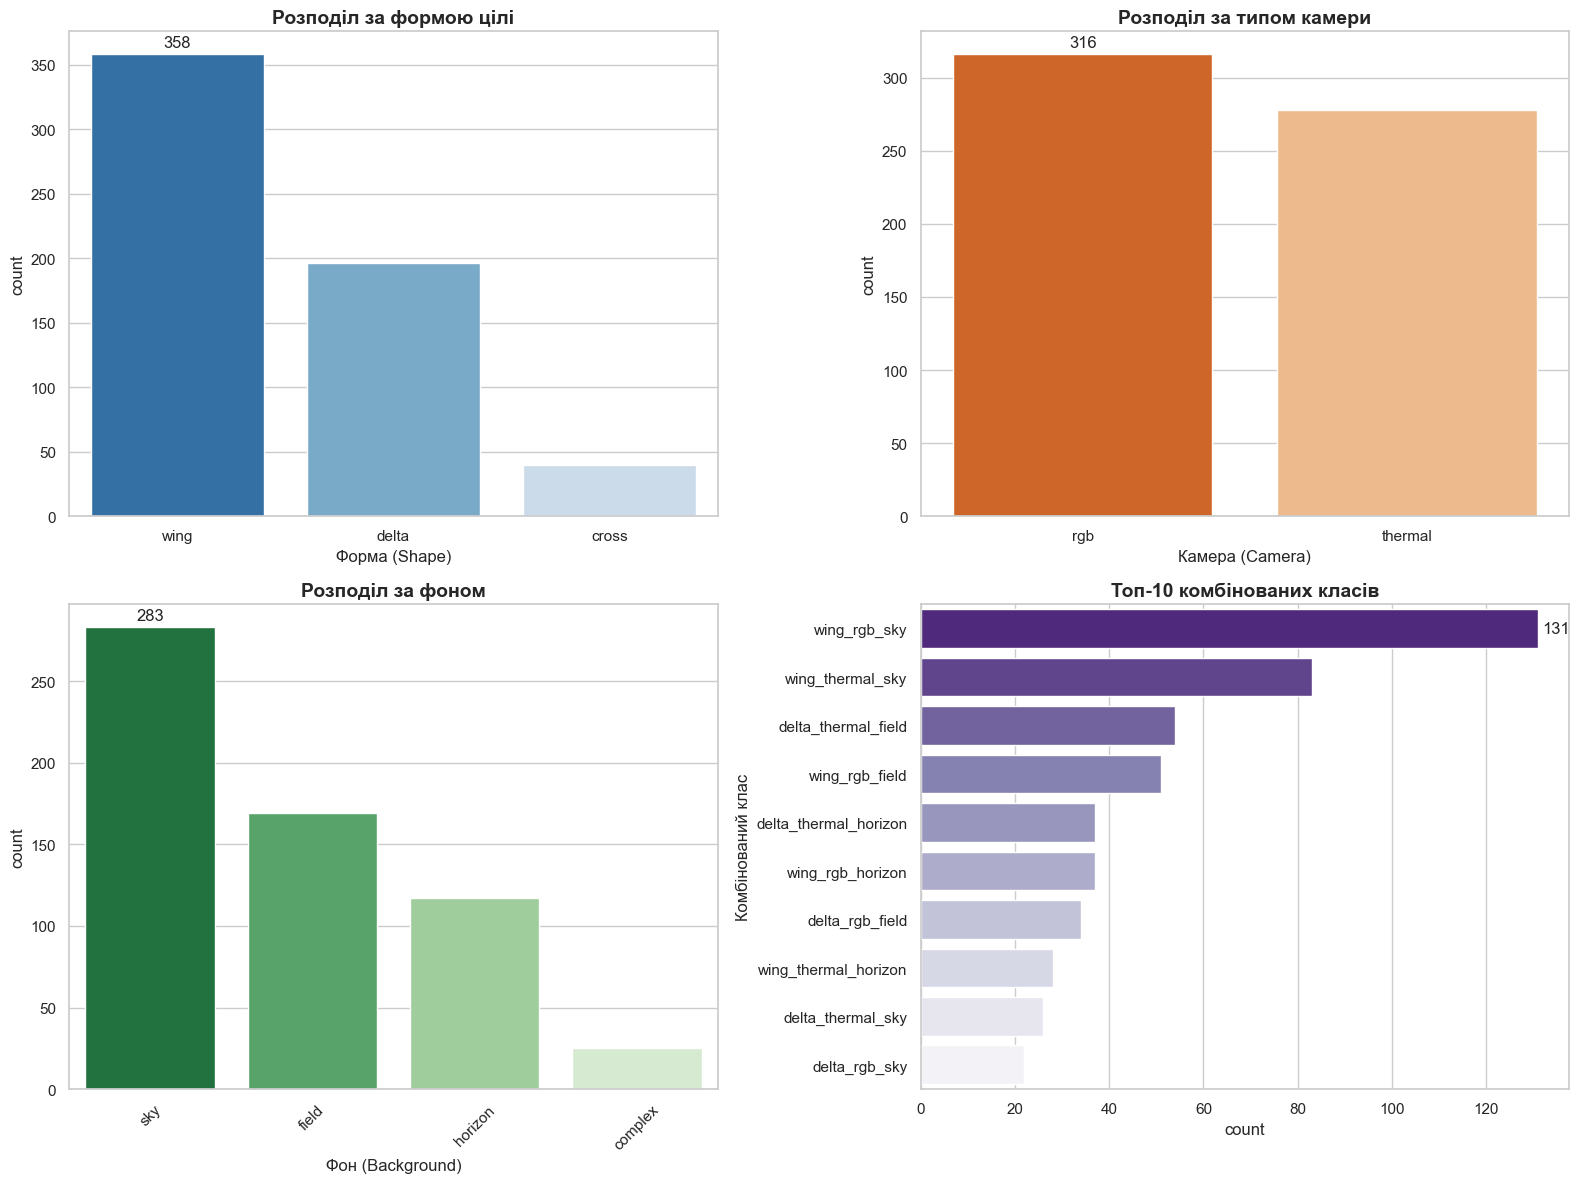

In [ ]:
# 3. Будуємо візуалізації
fig = plt.figure(figsize=(16, 12))

# Графік 1: Форма
ax1 = plt.subplot(2, 2, 1)
sns.countplot(data=df, x='Форма', order=df['Форма'].value_counts().index, ax=ax1, palette="Blues_r")
ax1.set_title('Розподіл за формою цілі', fontsize=14, fontweight='bold')
ax1.bar_label(ax1.containers[0], padding=3)

# Графік 2: Камера
ax2 = plt.subplot(2, 2, 2)
sns.countplot(data=df, x='Камера', order=df['Камера'].value_counts().index, ax=ax2, palette="Oranges_r")
ax2.set_title('Розподіл за типом камери', fontsize=14, fontweight='bold')
ax2.bar_label(ax2.containers[0], padding=3)

# Графік 3: Фон
ax3 = plt.subplot(2, 2, 3)
sns.countplot(data=df, x='Фон', order=df['Фон'].value_counts().index, ax=ax3, palette="Greens_r")
ax3.set_title('Розподіл за фоном', fontsize=14, fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
ax3.bar_label(ax3.containers[0], padding=3)

# Графік 4: Топ-10 комбінованих класів
ax4 = plt.subplot(2, 2, 4)
top_classes = df['Комбінований клас'].value_counts().nlargest(10).index
sns.countplot(data=df, y='Комбінований клас', order=top_classes, ax=ax4, palette="Purples_r")
ax4.set_title('Топ-10 комбінованих класів', fontsize=14, fontweight='bold')
ax4.bar_label(ax4.containers[0], padding=3)

plt.tight_layout()
plt.show()

In [25]:
import pandas as pd

# 1. Рахуємо кількість відео для кожної комбінації
counts = df['Комбінований клас'].value_counts()

# 2. Рахуємо відсотковий розподіл (нормалізуємо і множимо на 100)
percentages = df['Комбінований клас'].value_counts(normalize=True) * 100

# 3. Об'єднуємо дані в одну підсумкову таблицю
distribution_report = pd.DataFrame({
    'Кількість відео': counts,
    'Відсоток (%)': percentages.round(2) # Округлюємо до 2 знаків після коми
}).reset_index()

# Перейменовуємо колонки для красивого виведення
distribution_report.columns = ['Комбінований клас', 'Кількість відео', 'Відсоток (%)']

# --- Виведення фінального звіту ---
print("📊 КІЛЬКІСНИЙ ТА ВІДСОТКОВИЙ РОЗПОДІЛ КОМБІНАЦІЙ")
print("=" * 70)
print(f"Загальна кількість відео у вибірці: {len(df)}")
print("=" * 70)
print(distribution_report.to_string(index=False))
print("=" * 70)

📊 КІЛЬКІСНИЙ ТА ВІДСОТКОВИЙ РОЗПОДІЛ КОМБІНАЦІЙ
Загальна кількість відео у вибірці: 594
    Комбінований клас  Кількість відео  Відсоток (%)
         wing_rgb_sky              131         22.05
     wing_thermal_sky               83         13.97
  delta_thermal_field               54          9.09
       wing_rgb_field               51          8.59
delta_thermal_horizon               37          6.23
     wing_rgb_horizon               37          6.23
      delta_rgb_field               34          5.72
 wing_thermal_horizon               28          4.71
    delta_thermal_sky               26          4.38
        delta_rgb_sky               22          3.70
   wing_thermal_field               20          3.37
        cross_rgb_sky               11          1.85
    cross_thermal_sky               10          1.68
    delta_rgb_complex                9          1.52
    delta_rgb_horizon                8          1.35
delta_thermal_complex                6          1.01
      cross

In [30]:
import os
import pandas as pd

# ================= CONFIGURATION =================
SPLIT_DIR = r"E:\bachelor_data\dataset_split"
SPLITS = ['train', 'val', 'test']
# =================================================

def parse_filename(filename):
    name_no_ext = os.path.splitext(filename)[0]
    parts = name_no_ext.split('_')
    if len(parts) >= 3:
        return f"{parts[0]}_{parts[1]}_{parts[2]}"
    return None

print("[*] Starting stratification audit (PERCENTAGE VIEW)...\n")
all_data = []

# Gather data from split folders
for split in SPLITS:
    folder_path = os.path.join(SPLIT_DIR, split)
    if not os.path.exists(folder_path):
        print(f"[!] Warning: Folder '{split}' not found!")
        continue
        
    for filename in os.listdir(folder_path):
        combined_class = parse_filename(filename)
        if combined_class:
            all_data.append({
                'Class': combined_class,
                'Split': split.upper()
            })

df = pd.DataFrame(all_data)

if df.empty:
    print("[-] Error: No data found.")
else:
    # Build the base cross-tabulation with raw counts
    pivot_counts = pd.crosstab(df['Class'], df['Split'])
    
    # Calculate total videos per class
    row_totals = pivot_counts.sum(axis=1)
    
    # Convert raw counts to percentages (row-wise)
    pivot_pct = pivot_counts.div(row_totals, axis=0) * 100
    
    # Add the raw total count back for context
    pivot_pct['Total (Count)'] = row_totals
    
    # Sort by total count so the largest classes are at the top
    pivot_pct = pivot_pct.sort_values(by='Total (Count)', ascending=False)
    
    # Format the percentage columns to 1 decimal place with a '%' sign
    for col in pivot_counts.columns:
        pivot_pct[col] = pivot_pct[col].apply(lambda x: f"{x:.1f}%")

    print("[*] CLASS DISTRIBUTION BY SPLIT (PERCENTAGES):")
    print("=" * 75)
    
    # Dynamic column ordering to prevent KeyError
    expected_columns = ['TRAIN', 'VAL', 'TEST', 'Total (Count)']
    available_columns = [col for col in expected_columns if col in pivot_pct.columns]
    
    print(pivot_pct[available_columns].to_string())
    print("=" * 75)
    
    print("\n[i] Expected distribution: ~70.0% / ~15.0% / ~15.0%")
    print("[i] Note: Rare classes (< 6 videos) were forced 100.0% into TRAIN to prevent math errors.")

[*] Starting stratification audit (PERCENTAGE VIEW)...

[*] CLASS DISTRIBUTION BY SPLIT (PERCENTAGES):
Split                   TRAIN    VAL   TEST  Total (Count)
Class                                                     
wing_rgb_sky            69.5%  15.3%  15.3%            131
wing_thermal_sky        69.9%  14.5%  15.7%             83
delta_thermal_field     70.4%  14.8%  14.8%             54
wing_rgb_field          70.6%  13.7%  15.7%             51
wing_rgb_horizon        70.3%  13.5%  16.2%             37
delta_thermal_horizon   70.3%  13.5%  16.2%             37
delta_rgb_field         70.6%  14.7%  14.7%             34
wing_thermal_horizon    67.9%  14.3%  17.9%             28
delta_thermal_sky       69.2%  15.4%  15.4%             26
delta_rgb_sky           68.2%  18.2%  13.6%             22
wing_thermal_field      70.0%  15.0%  15.0%             20
cross_rgb_sky           72.7%  18.2%   9.1%             11
cross_thermal_sky       70.0%  20.0%  10.0%             10
delta_rgb_co

[*] Starting stratification audit and visualization...



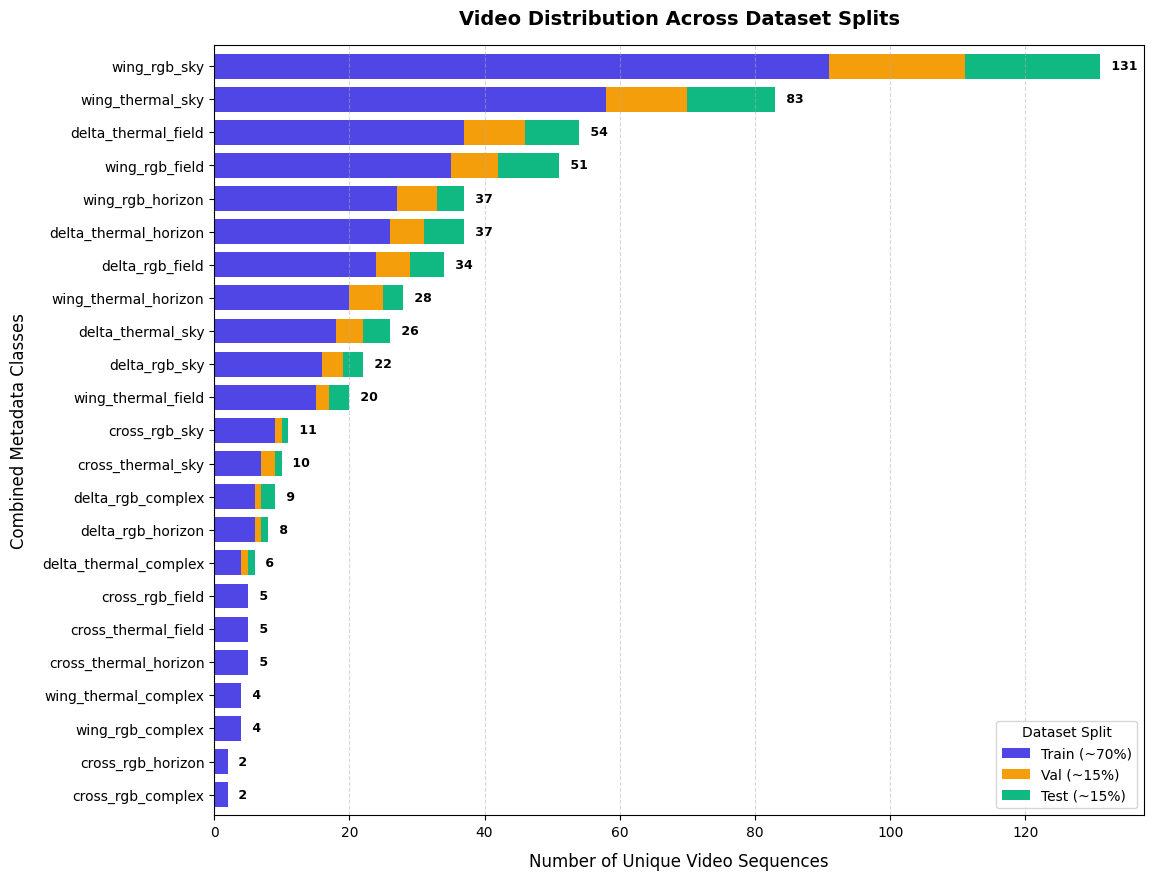

[+] Stratification distribution chart successfully saved to: model_analysis/stratification_distribution.png


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ================= CONFIGURATION =================
SPLIT_DIR = r"E:\bachelor_data\dataset_split"
SPLITS = ['train', 'val', 'test']
OUTPUT_PLOT_PATH = "model_analysis/stratification_distribution.png"
# =================================================

def parse_filename(filename):
    name_no_ext = os.path.splitext(filename)[0]
    parts = name_no_ext.split('_')
    if len(parts) >= 3:
        return f"{parts[0]}_{parts[1]}_{parts[2]}"
    return None

def generate_distribution_chart():
    print("[*] Starting stratification audit and visualization...\n")
    all_data = []

    # Gather data from split folders
    for split in SPLITS:
        folder_path = os.path.join(SPLIT_DIR, split)
        if not os.path.exists(folder_path):
            print(f"[!] Warning: Folder '{split}' not found!")
            continue
            
        for filename in os.listdir(folder_path):
            combined_class = parse_filename(filename)
            if combined_class:
                all_data.append({
                    'Class': combined_class,
                    'Split': split.upper()
                })

    df = pd.DataFrame(all_data)

    if df.empty:
        print("[-] Error: No data found.")
        return

    # Create cross-tabulation table with raw counts
    pivot_counts = pd.crosstab(df['Class'], df['Split'])
    
    # Ensure correct order of splits in the columns
    available_splits = [col for col in ['TRAIN', 'VAL', 'TEST'] if col in pivot_counts.columns]
    pivot_counts = pivot_counts[available_splits]
    
    # Calculate totals per class for sorting
    pivot_counts['Total'] = pivot_counts.sum(axis=1)
    
    # Sort classes from largest to smallest to make the plot clean and readable
    pivot_counts = pivot_counts.sort_values(by='Total', ascending=True)
    
    # Drop the total column before plotting to keep only split segments
    plot_data = pivot_counts.drop(columns=['Total'])

    # Initialize the plot with clear, readable dimensions
    plt.figure(figsize=(12, 10))
    
    # Soft, professional, academic color palette
    # Train: Indigo Blue, Val: Amber Orange, Test: Emerald Green
    colors = ['#4f46e5', '#f59e0b', '#10b981']
    
    # Build Horizontal Stacked Bar Chart
    plot_data.plot(
        kind='barh', 
        stacked=True, 
        color=colors[:len(available_splits)], 
        ax=plt.gca(), 
        width=0.75
    )
    
    # Add values on top of the bars to make it highly informative
    for i, (idx, row) in enumerate(pivot_counts.iterrows()):
        total = int(row['Total'])
        # Place the total text slightly to the right of the stacked bar
        plt.text(total + 1, i, f" {total}", va='center', ha='left', fontsize=9, fontweight='bold')

    # Styling the plot for thesis publication standards
    plt.title('Video Distribution Across Dataset Splits', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Number of Unique Video Sequences', fontsize=12, labelpad=10)
    plt.ylabel('Combined Metadata Classes', fontsize=12, labelpad=10)
    plt.legend(title='Dataset Split', labels=['Train (~70%)', 'Val (~15%)', 'Test (~15%)'], loc='lower right')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    
    # Save the plot securely to your analysis directory
    os.makedirs(os.path.dirname(OUTPUT_PLOT_PATH), exist_ok=True)
    plt.savefig(OUTPUT_PLOT_PATH, bbox_inches='tight', dpi=300)
    plt.show()
    
    print(f"[+] Stratification distribution chart successfully saved to: {OUTPUT_PLOT_PATH}")


if __name__ == "__main__":
    generate_distribution_chart()

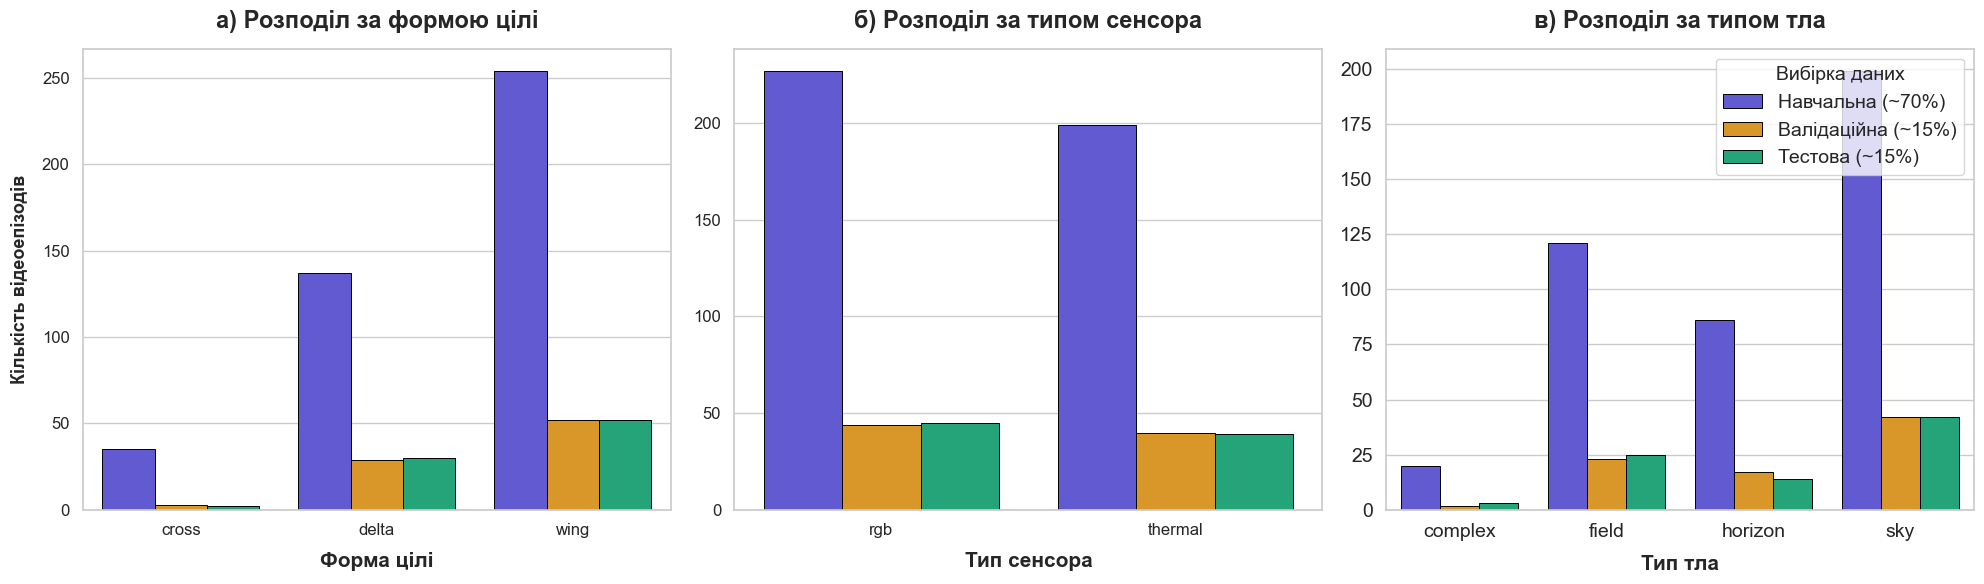

[+] Clean stratification report chart successfully saved to: model_analysis/stratification_grouped_report_ua.png


In [19]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ================= CONFIGURATION =================
SPLIT_DIR = r"E:\bachelor_data\dataset_split"
SPLITS = ['train', 'val', 'test']
OUTPUT_PLOT_PATH = "model_analysis/stratification_grouped_report_ua.png"
# =================================================

def parse_filename_attributes(filename):
    """Parses filename into individual clean attributes safely."""
    name_no_ext = os.path.splitext(filename)[0]
    parts = name_no_ext.split('_')
    
    # Safely handle 'no_drone' negative samples (length is at least 4 due to 'no' and 'drone' split)
    if len(parts) >= 4 and parts[0] == "no" and parts[1] == "drone":
        return {
            "Morphology": "no_drone",
            "Camera": parts[2],
            "Background": parts[3]
        }
    # Standard positive samples (original fallback requires at least 3 parts)
    elif len(parts) >= 3:
        return {
            "Morphology": parts[0],
            "Camera": parts[1],
            "Background": parts[2]
        }
    return None

def generate_grouped_distribution_chart():
    all_data = []

    # Gather data from split folders
    for split in SPLITS:
        folder_path = os.path.join(SPLIT_DIR, split)
        if not os.path.exists(folder_path):
            print(f"[!] Warning: Folder '{split}' not found!")
            continue
            
        for filename in os.listdir(folder_path):
            attrs = parse_filename_attributes(filename)
            if attrs:
                attrs['Split'] = split.upper()
                all_data.append(attrs)

    df = pd.DataFrame(all_data)

    if df.empty:
        print("[-] Error: No data found. Please verify SPLIT_DIR folder paths.")
        return

    # Set up Seaborn style
    sns.set_theme(style="whitegrid")
    
    # Initialize the composite 1x3 subplot grid with slightly larger size for readability
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    # Unified professional color palette
    # Train: Indigo Blue, Val: Amber Orange, Test: Emerald Green
    colors = ['#4f46e5', '#f59e0b', '#10b981']
    hue_order = ['TRAIN', 'VAL', 'TEST']

    # --- PLOT 1: MORPHOLOGY DISTRIBUTION ---
    sns.countplot(
        data=df, 
        x='Morphology', 
        hue='Split', 
        hue_order=hue_order,
        palette=colors, 
        ax=axes[0],
        edgecolor='black',
        linewidth=0.7
    )
    axes[0].set_title('а) Розподіл за формою цілі', fontsize=17, fontweight='bold', pad=15)
    axes[0].set_xlabel('Форма цілі', fontsize=15, fontweight='bold', labelpad=10)
    axes[0].set_ylabel('Кількість відеоепізодів', fontsize=13, fontweight='bold', labelpad=10)
    axes[0].tick_params(axis='both', which='major', labelsize=12)
    
    # Remove legend to prevent redundancy
    legend = axes[0].get_legend()
    if legend:
        legend.remove()

    # --- PLOT 2: CAMERA TYPE DISTRIBUTION ---
    sns.countplot(
        data=df, 
        x='Camera', 
        hue='Split', 
        hue_order=hue_order,
        palette=colors, 
        ax=axes[1],
        edgecolor='black',
        linewidth=0.7
    )
    axes[1].set_title('б) Розподіл за типом сенсора', fontsize=17, fontweight='bold', pad=15)
    axes[1].set_xlabel('Тип сенсора', fontsize=15, fontweight='bold', labelpad=10)
    axes[1].set_ylabel('')
    axes[1].tick_params(axis='both', which='major', labelsize=12)
    
    legend = axes[1].get_legend()
    if legend:
        legend.remove()

    # --- PLOT 3: BACKGROUND TYPE DISTRIBUTION ---
    sns.countplot(
        data=df, 
        x='Background', 
        hue='Split', 
        hue_order=hue_order,
        palette=colors, 
        ax=axes[2],
        edgecolor='black',
        linewidth=0.7
    )
    # NATIVE TERMINOLOGY: Updated "тип фону" to "тип тла"
    axes[2].set_title('в) Розподіл за типом тла', fontsize=17, fontweight='bold', pad=15)
    axes[2].set_xlabel('Тип тла', fontsize=15, fontweight='bold', labelpad=10)
    axes[2].set_ylabel('')
    axes[2].tick_params(axis='both', which='major', labelsize=14)
    
    # Unified legend with large fonts (translated to Ukrainian)
    axes[2].legend(
        title='Вибірка даних', 
        title_fontsize=14,
        labels=['Навчальна (~70%)', 'Валідаційна (~15%)', 'Тестова (~15%)'], 
        loc='upper right',
        fontsize=14
    )

    plt.tight_layout()
    
    # Save the clean plot
    os.makedirs(os.path.dirname(OUTPUT_PLOT_PATH), exist_ok=True)
    plt.savefig(OUTPUT_PLOT_PATH, bbox_inches='tight', dpi=300)
    plt.show()
    
    print(f"[+] Clean stratification report chart successfully saved to: {OUTPUT_PLOT_PATH}")

if __name__ == "__main__":
    generate_grouped_distribution_chart()

In [1]:
import os
import cv2
import random

# ================= CONFIGURATION =================
SOURCE_DATASET_DIR = "E:/bachelor_data/extracted_dataset"
VERIFICATION_OUTPUT_DIR = "E:/bachelor_data/visual_checks"
SPLITS = ['train', 'val', 'test']
SAMPLES_PER_SPLIT = 20 # Number of random images to verify per split
# =================================================

os.makedirs(VERIFICATION_OUTPUT_DIR, exist_ok=True)

def draw_yolo_boxes(image_path, label_path):
    """Reads YOLO label and draws boxes on the image."""
    image = cv2.imread(image_path)
    if image is None:
        return None
    
    height, width, _ = image.shape
    
    if not os.path.exists(label_path):
        return image

    with open(label_path, 'r') as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()
        if len(parts) != 5:
            continue
        
        # YOLO format: class_id, cx, cy, w, h
        _, cx, cy, w, h = map(float, parts)

        # Convert normalized coordinates back to pixel coordinates
        center_x = cx * width
        center_y = cy * height
        bbox_width = w * width
        bbox_height = h * height

        x1 = int(center_x - bbox_width / 2)
        y1 = int(center_y - bbox_height / 2)
        x2 = int(center_x + bbox_width / 2)
        y2 = int(center_y + bbox_height / 2)

        # Draw green box
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        # Draw class label (drone)
        cv2.putText(image, "drone", (x1, y1 - 10), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    
    return image

print("Starting visual verification...")

for split in SPLITS:
    pos_dir = os.path.join(SOURCE_DATASET_DIR, split, "RAW_POSITIVES")
    output_split_dir = os.path.join(VERIFICATION_OUTPUT_DIR, split)
    os.makedirs(output_split_dir, exist_ok=True)

    if not os.path.exists(pos_dir):
        print(f"Directory not found: {pos_dir}")
        continue

    # Get list of all images in the positive folder
    all_images = [f for f in os.listdir(pos_dir) if f.endswith('.jpg')]
    
    if not all_images:
        print(f"No images found in {pos_dir}")
        continue

    # Select random samples
    sample_images = random.sample(all_files := all_images, min(SAMPLES_PER_SPLIT, len(all_images)))

    print(f"Processing split '{split}': {len(sample_images)} samples...")

    for img_name in sample_images:
        img_path = os.path.join(pos_dir, img_name)
        lbl_path = os.path.join(pos_dir, img_name.replace('.jpg', '.txt'))
        
        verified_img = draw_yolo_boxes(img_path, lbl_path)
        
        if verified_img is not None:
            cv2.imwrite(os.path.join(output_split_dir, f"check_{img_name}"), verified_img)

print("\n" + "="*50)
print(f"VERIFICATION COMPLETE. Previews saved in: {VERIFICATION_OUTPUT_DIR}")
print("Please open the images and check if the green boxes match the drones.")

Starting visual verification...
Processing split 'train': 20 samples...
Processing split 'val': 20 samples...
Processing split 'test': 20 samples...

VERIFICATION COMPLETE. Previews saved in: E:/bachelor_data/visual_checks
Please open the images and check if the green boxes match the drones.


In [3]:
import os
import glob
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()

# ================= CONFIGURATION =================
DATASET_ROOT = os.getenv("PROCESSED_DATA_PATH", "E:/bachelor_data/extracted_dataset")
SPLITS = ['train', 'val', 'test']
# =================================================

def check_class_ids():
    print(f"Scanning labels in: {DATASET_ROOT}")
    
    global_found_ids = set()
    files_with_anomalies = []
    total_files_checked = 0

    for split in SPLITS:
        pos_dir = os.path.join(DATASET_ROOT, split, "RAW_POSITIVES")
        if not os.path.exists(pos_dir):
            print(f"Skipping {split}: folder not found.")
            continue

        label_files = glob.glob(os.path.join(pos_dir, "*.txt"))
        print(f"Checking {split.upper()}... ({len(label_files)} files)")

        for lbl_path in label_files:
            total_files_checked += 1
            with open(lbl_path, 'r') as f:
                lines = f.readlines()
                for line in lines:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    
                    class_id = parts[0]
                    global_found_ids.add(class_id)
                    
                    # Якщо ID не "0", записуємо цей файл для звіту
                    if class_id != "0":
                        files_with_anomalies.append((lbl_path, class_id))

    print("\n" + "="*50)
    print("RESULTS:")
    print(f"Total .txt files checked: {total_files_checked}")
    print(f"Unique Class IDs found: {sorted(list(global_found_ids))}")
    
    if len(global_found_ids) == 1 and "0" in global_found_ids:
        print("✅ SUCCESS: All labels have class ID '0'.")
    else:
        print(f"⚠️ WARNING: Found unexpected class IDs!")
        if files_with_anomalies:
            print("\nFirst 10 anomalies (File -> Found ID):")
            for path, found_id in files_with_anomalies[:10]:
                print(f"{os.path.basename(path)} -> ID: {found_id}")
            if len(files_with_anomalies) > 10:
                print(f"... and {len(files_with_anomalies) - 10} more files.")
    print("="*50)

if __name__ == "__main__":
    check_class_ids()

Scanning labels in: E:/bachelor_data/extracted_dataset
Checking TRAIN... (45024 files)
Checking VAL... (7907 files)
Checking TEST... (8479 files)

RESULTS:
Total .txt files checked: 61410
Unique Class IDs found: ['0']
✅ SUCCESS: All labels have class ID '0'.


### **Аналіз розподілу роздільних здатностей тренувальної вибірки без негативів!!!**

d:\anykn\python\bachelor\drone_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Analyzing 8,228 positive samples in split: 'TRAIN'



Scanning Dataset Geometry: 100%|██████████| 8228/8228 [02:00<00:00, 68.52it/s]
C:\Users\anykn\AppData\Local\Temp\ipykernel_3020\2799838907.py:186: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



IMAGE DIMENSIONS & SHAPES REPORT
Total Unique Resolutions: 12

Resolution Distribution Count:
width  height
1920   1080      2027
1350   1080      1963
848    544       1743
1280   720       1383
848    464        257
       640        227
       656        221
1920   1072       220
848    496         62
       480         51
1280   1040        40
848    576         34
dtype: int64

Image Aspect Ratio Statistics:
count    8228.000000
mean        1.577366
std         0.224470
min         1.230769
10%         1.250000
25%         1.292683
50%         1.558824
75%         1.777778
90%         1.777778
max         1.827586
Name: aspect_ratio, dtype: float64

TARGET (BBOX) GEOMETRY REPORT
Total Bounding Boxes Analyzed: 8228

Bounding Box Width (pixels):
count    8228.000000
mean      498.262223
std       431.779368
min         4.999680
10%        85.999920
25%       172.969440
50%       360.000000
75%       705.000960
90%      1130.300253
max      1920.000000
Name: pixel_width, dtype: floa

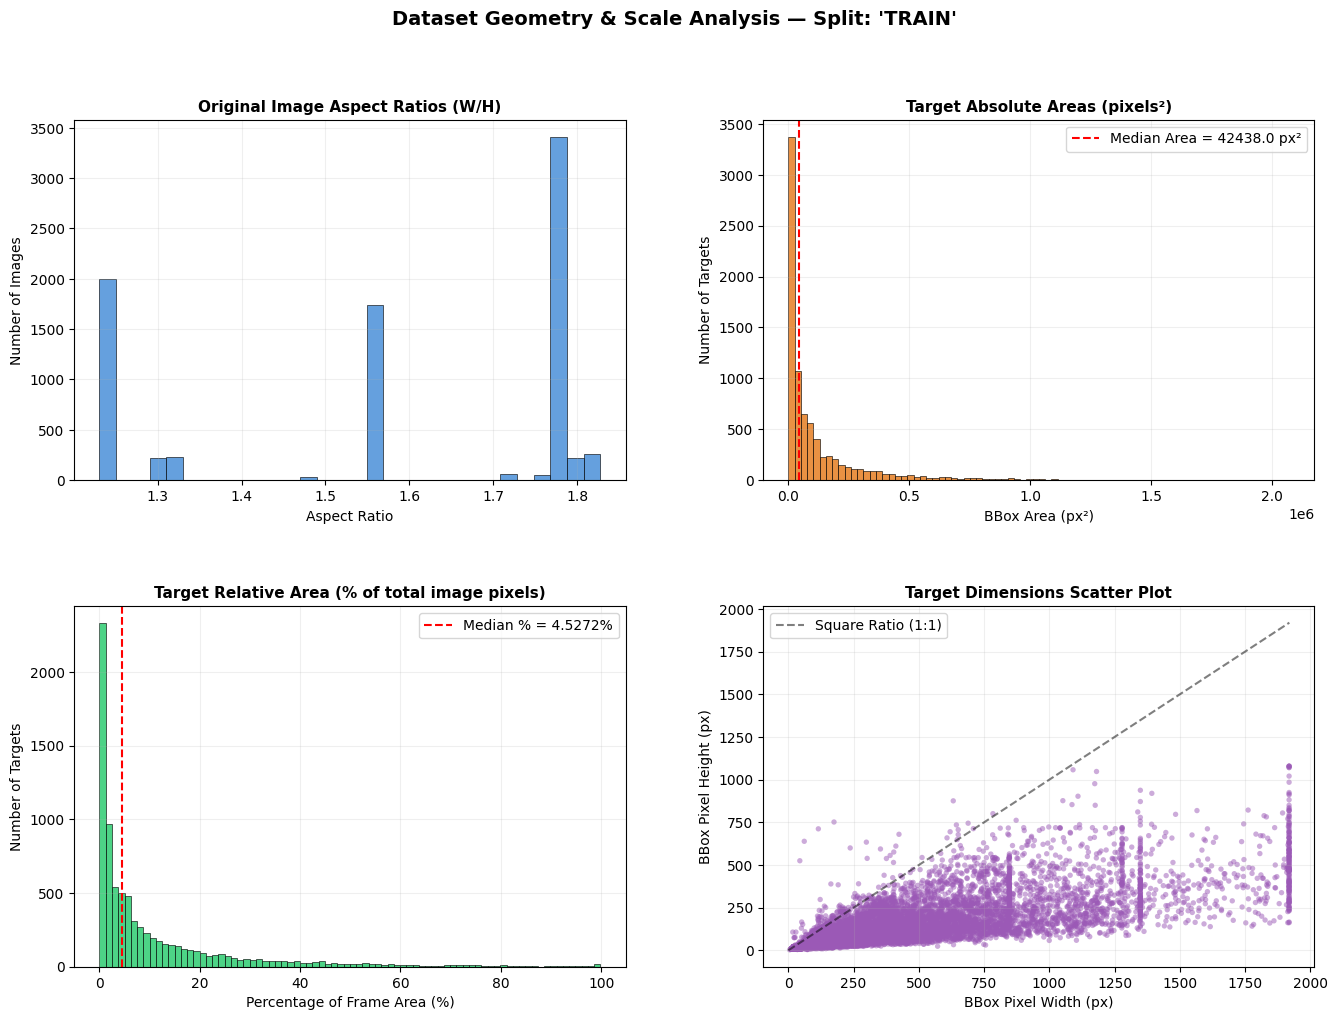

In [1]:
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from dotenv import load_dotenv

load_dotenv()

# ================= CONFIGURATION =================
EXTRACTED_DATA_PATH = os.getenv("EXTRACTED_DATA_PATH")
TARGET_SPLIT = "train"  # Analysis is performed on the training split
# =================================================

def analyze_dataset_geometry(extracted_path_str: str, split: str):
    pos_dir = Path(extracted_path_str) / split / "RAW_POSITIVES"
    if not pos_dir.exists():
        print(f"Error: Target directory not found: {pos_dir}")
        return

    # Find all positive images
    image_paths = sorted(glob.glob(str(pos_dir / "*.jpg")))
    print(f"Analyzing {len(image_paths):,} positive samples in split: '{split.upper()}'\n")

    # Arrays to accumulate geometry statistics
    img_widths = []
    img_heights = []
    img_aspect_ratios = []
    
    bbox_pixel_widths = []
    bbox_pixel_heights = []
    bbox_pixel_areas = []
    bbox_relative_areas = []  # % of total frame area
    bbox_aspect_ratios = []

    # Process all image-label pairs with progress bar
    for img_path_str in tqdm(image_paths, desc="Scanning Dataset Geometry"):
        img_path = Path(img_path_str)
        lbl_path = img_path.with_suffix(".txt")

        # 1. Quickly read image dimensions using PIL header scanner (no full image load)
        try:
            with Image.open(img_path) as img:
                w, h = img.size
        except Exception as e:
            print(f"Warning: Failed to read image {img_path.name}: {e}")
            continue

        img_widths.append(w)
        img_heights.append(h)
        img_aspect_ratios.append(w / h)

        # 2. Parse bounding boxes if label file exists
        if lbl_path.exists():
            try:
                with open(lbl_path, "r") as f:
                    lines = f.readlines()
                
                for line in lines:
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue
                    
                    # YOLO format: class_id, cx, cy, normalized_w, hn
                    _, _, _, nw, nh = map(float, parts)

                    # Convert normalized coordinates back to actual pixels
                    pixel_w = nw * w
                    pixel_h = nh * h
                    pixel_area = pixel_w * pixel_h
                    
                    # Relative area as a percentage of total frame pixels
                    relative_area = (pixel_area / (w * h)) * 100

                    bbox_pixel_widths.append(pixel_w)
                    bbox_pixel_heights.append(pixel_h)
                    bbox_pixel_areas.append(pixel_area)
                    bbox_relative_areas.append(relative_area)
                    bbox_aspect_ratios.append(pixel_w / (pixel_h + 1e-8))
            except Exception as e:
                print(f"Warning: Failed to parse label {lbl_path.name}: {e}")

    # Create pandas DataFrames for easy statistical modeling
    df_images = pd.DataFrame({
        "width": img_widths,
        "height": img_heights,
        "aspect_ratio": img_aspect_ratios
    })

    df_bboxes = pd.DataFrame({
        "pixel_width": bbox_pixel_widths,
        "pixel_height": bbox_pixel_heights,
        "pixel_area": bbox_pixel_areas,
        "relative_area_pct": bbox_relative_areas,
        "aspect_ratio": bbox_aspect_ratios
    })

    # -------------------------------------------------
    # PRINT GEOMETRY REPORTS
    # -------------------------------------------------
    print("\n" + "="*60)
    print("IMAGE DIMENSIONS & SHAPES REPORT")
    print("="*60)
    print(f"Total Unique Resolutions: {df_images.groupby(['width', 'height']).size().count()}")
    print("\nResolution Distribution Count:")
    print(df_images.groupby(['width', 'height']).size().sort_values(ascending=False))
    
    print("\nImage Aspect Ratio Statistics:")
    print(df_images["aspect_ratio"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

    print("\n" + "="*60)
    print("TARGET (BBOX) GEOMETRY REPORT")
    print("="*60)
    print(f"Total Bounding Boxes Analyzed: {len(df_bboxes)}")
    
    print("\nBounding Box Width (pixels):")
    print(df_bboxes["pixel_width"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

    print("\nBounding Box Height (pixels):")
    print(df_bboxes["pixel_height"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

    print("\nBounding Box Area (pixels²):")
    print(df_bboxes["pixel_area"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

    print("\nBounding Box Relative Area (% of total image area):")
    print(df_bboxes["relative_area_pct"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

    # -------------------------------------------------
    # PLOT GEOMETRY DISTRIBUTION GRAPHS
    # -------------------------------------------------
    fig = plt.figure(figsize=(16, 11))
    fig.suptitle(f"Dataset Geometry & Scale Analysis — Split: '{split.upper()}'", fontsize=14, fontweight="bold")
    
    # 2x2 grid layout
    import matplotlib.gridspec as gridspec
    gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.25)

    # Plot 1: Image Aspect Ratios
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.hist(df_images["aspect_ratio"], bins=30, color="#4A90D9", alpha=0.85, edgecolor="black", linewidth=0.5)
    ax1.set_title("Original Image Aspect Ratios (W/H)", fontsize=11, fontweight="bold")
    ax1.set_xlabel("Aspect Ratio")
    ax1.set_ylabel("Number of Images")
    ax1.grid(True, alpha=0.2)

    # Plot 2: Bounding Box Absolute Pixel Areas
    ax2 = fig.add_subplot(gs[0, 1])
    # Using log scale for area distribution as small targets might skew the histogram
    ax2.hist(df_bboxes["pixel_area"], bins=80, color="#E67E22", alpha=0.85, edgecolor="black", linewidth=0.5)
    ax2.set_title("Target Absolute Areas (pixels²)", fontsize=11, fontweight="bold")
    ax2.set_xlabel("BBox Area (px²)")
    ax2.set_ylabel("Number of Targets")
    ax2.grid(True, alpha=0.2)
    # Highlight median size
    median_area = df_bboxes["pixel_area"].median()
    ax2.axvline(median_area, color="red", linestyle="--", label=f"Median Area = {median_area:.1f} px²")
    ax2.legend()

    # Plot 3: Bounding Box Relative Areas (%)
    ax3 = fig.add_subplot(gs[1, 0])
    ax3.hist(df_bboxes["relative_area_pct"], bins=80, color="#2ECC71", alpha=0.85, edgecolor="black", linewidth=0.5)
    ax3.set_title("Target Relative Area (% of total image pixels)", fontsize=11, fontweight="bold")
    ax3.set_xlabel("Percentage of Frame Area (%)")
    ax3.set_ylabel("Number of Targets")
    ax3.grid(True, alpha=0.2)
    median_pct = df_bboxes["relative_area_pct"].median()
    ax3.axvline(median_pct, color="red", linestyle="--", label=f"Median % = {median_pct:.4f}%")
    ax3.legend()

    # Plot 4: Scatter Plot of Target Dimensions (Width vs Height)
    ax4 = fig.add_subplot(gs[1, 1])
    ax4.scatter(df_bboxes["pixel_width"], df_bboxes["pixel_height"], color="#9B59B6", alpha=0.5, edgecolors="none", s=15)
    ax4.set_title("Target Dimensions Scatter Plot", fontsize=11, fontweight="bold")
    ax4.set_xlabel("BBox Pixel Width (px)")
    ax4.set_ylabel("BBox Pixel Height (px)")
    ax4.grid(True, alpha=0.2)
    
    # Plot diagonal line representing perfect 1:1 aspect ratio targets (squares)
    max_dim = max(df_bboxes["pixel_width"].max(), df_bboxes["pixel_height"].max())
    ax4.plot([0, max_dim], [0, max_dim], color="black", linestyle="--", alpha=0.5, label="Square Ratio (1:1)")
    ax4.legend()

    plt.tight_layout()
    plt.show()

# Run the geometrical analysis pipeline on your local machine
analyze_dataset_geometry(EXTRACTED_DATA_PATH, TARGET_SPLIT)

In [2]:
import re
import os
import glob
from pathlib import Path
from collections import defaultdict

EXTRACTED_DATA_DIR = Path(os.getenv("EXTRACTED_DATA_PATH"))

for split in ["train", "val", "test"]:
    for subdir, label in [("RAW_POSITIVES", "positives"),
                           ("RAW_NEGATIVES", "negatives")]:
        target = EXTRACTED_DATA_DIR / split / subdir
        if not target.exists():
            continue

        pattern = "*.txt" if label == "positives" else "*.jpg"
        files = glob.glob(str(target / pattern))

        groups = defaultdict(int)
        for f in files:
            stem = Path(f).stem
            v_id = re.sub(r'_f\d+$', '', stem)
            groups[v_id] += 1

        sizes = sorted(groups.values())
        if not sizes:
            continue

        import numpy as np
        print(f"\n{split.upper()} / {label}")
        print(f"  Відео: {len(sizes)}")
        print(f"  Кадрів всього: {sum(sizes)}")
        print(f"  Мін: {min(sizes)}  Макс: {max(sizes)}")
        print(f"  Медіана: {np.median(sizes):.0f}  Середнє: {np.mean(sizes):.0f}")
        print(f"  p25: {np.percentile(sizes,25):.0f}  p75: {np.percentile(sizes,75):.0f}")


TRAIN / positives
  Відео: 423
  Кадрів всього: 8177
  Мін: 2  Макс: 103
  Медіана: 16  Середнє: 19
  p25: 11  p75: 23

TRAIN / negatives
  Відео: 69
  Кадрів всього: 810
  Мін: 1  Макс: 144
  Медіана: 3  Середнє: 12
  p25: 1  p75: 8

VAL / positives
  Відео: 84
  Кадрів всього: 6035
  Мін: 14  Макс: 303
  Медіана: 57  Середнє: 72
  p25: 34  p75: 93

VAL / negatives
  Відео: 14
  Кадрів всього: 1047
  Мін: 1  Макс: 474
  Медіана: 6  Середнє: 75
  p25: 2  p75: 24

TEST / positives
  Відео: 84
  Кадрів всього: 6748
  Мін: 19  Макс: 292
  Медіана: 62  Середнє: 80
  p25: 42  p75: 105

TEST / negatives
  Відео: 14
  Кадрів всього: 1134
  Мін: 2  Макс: 840
  Медіана: 6  Середнє: 81
  p25: 3  p75: 42


[*] Starting spatial coordinate analysis...
    Scanning dataset directory: E:\bachelor_data\extracted_dataset
[*] Found 12,000 positive label files. Extracting coordinates...

           SPATIAL COORDINATE METRICS               
Total Bounding Boxes Parsed: 12,000
X Center Mean (Width)      : 0.5091 (Std Dev: 0.1250)
Y Center Mean (Height)     : 0.4298 (Std Dev: 0.2204)


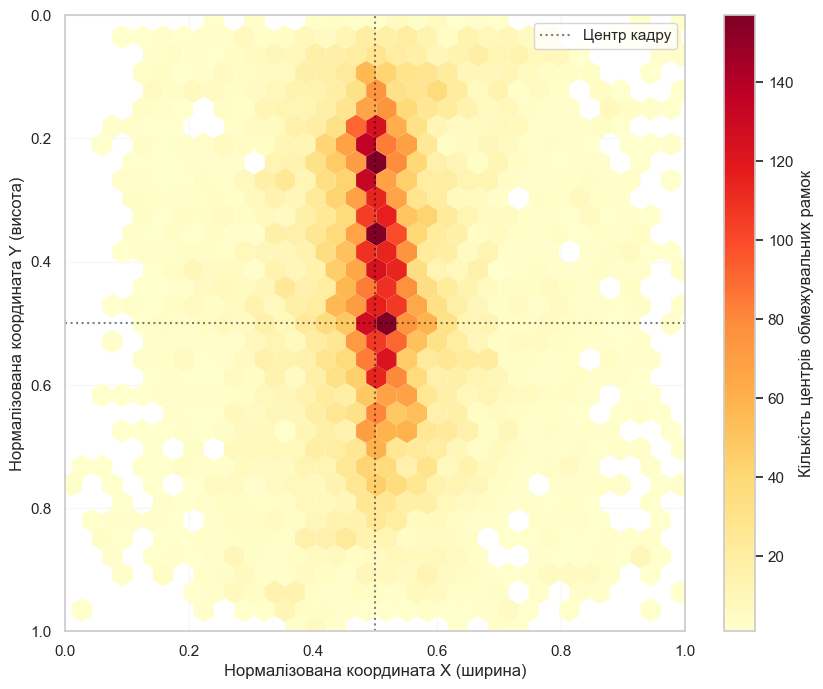


[+] Successfully generated spatial heatmap.
    Saved visual report to: 'D:\anykn\python\bachelor\drone_classification\notebooks\model_analysis\bbox_spatial_heatmap.png'


In [15]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from dotenv import load_dotenv

load_dotenv()

# =====================================================================
# CONFIGURATION
# Set the path to your final flat dataset folder (e.g., cropped_dataset)
# =====================================================================
DATASET_DIR = Path(os.getenv("EXTRACTED_DATA_PATH"))

OUTPUT_DIR = Path("./model_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def generate_spatial_heatmap():
    print(f"[*] Starting spatial coordinate analysis...")
    print(f"    Scanning dataset directory: {DATASET_DIR.resolve()}")
    
    splits = ["train", "val", "test"]
    label_paths = []
    
    for split in splits:
        positives_dir = DATASET_DIR / split / "RAW_POSITIVES"
        if positives_dir.exists():
            label_paths.extend(list(positives_dir.glob("*.txt")))
            
    total_labels = len(label_paths)
    if total_labels == 0:
        print(f"[!] Error: No YOLO .txt label files found in: {DATASET_DIR}")
        print("    Please check if the path is correct and contains RAW_POSITIVES directories.")
        return

    print(f"[*] Found {total_labels:,} positive label files. Extracting coordinates...")

    x_centers = []
    y_centers = []
    total_boxes = 0

    # Parse normalized YOLO coordinates (cx, cy) from txt files
    for path in label_paths:
        try:
            with open(path, "r") as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        # YOLO format: class_id x_center y_center width height
                        x_c = float(parts[1])
                        y_c = float(parts[2])
                        
                        # Clip values to [0.0, 1.0] to handle potential boundary errors
                        x_centers.append(np.clip(x_c, 0.0, 1.0))
                        y_centers.append(np.clip(y_c, 0.0, 1.0))
                        total_boxes += 1
        except Exception as e:
            print(f"  [WARNING] Failed to parse file {path.name}: {e}")

    if total_boxes == 0:
        print("[!] Error: No valid bounding boxes were parsed.")
        return

    x_centers = np.array(x_centers)
    y_centers = np.array(y_centers)

    # Calculate spatial statistical metrics
    mean_x, std_x = np.mean(x_centers), np.std(x_centers)
    mean_y, std_y = np.mean(y_centers), np.std(y_centers)

    print("\n" + "="*50)
    print("           SPATIAL COORDINATE METRICS               ")
    print("====================================================")
    print(f"Total Bounding Boxes Parsed: {total_boxes:,}")
    print(f"X Center Mean (Width)      : {mean_x:.4f} (Std Dev: {std_x:.4f})")
    print(f"Y Center Mean (Height)     : {mean_y:.4f} (Std Dev: {std_y:.4f})")
    print("====================================================")

    # -----------------------------------------------------------------
    # PLOTTING THE SPATIAL HEATMAP
    # -----------------------------------------------------------------
    fig = plt.figure(figsize=(10, 8))
    
    # 2D Hexagonal Binning Heatmap
    # Y-axis is inverted to match standard computer vision coordinates (0,0 is Top-Left)
    hb = plt.hexbin(
        x_centers, y_centers, 
        gridsize=30, 
        cmap="YlOrRd", 
        mincnt=1, 
        edgecolors="none"
    )
    
    # Add colorbar to indicate density scale
    cb = plt.colorbar(hb, label="Кількість центрів обмежувальних рамок")
    
    # Draw reference center crosshairs
    plt.axvline(0.5, color="black", linestyle=":", alpha=0.5, label="Центр кадру")
    plt.axhline(0.5, color="black", linestyle=":", alpha=0.5)

    # Format Axes to represent normalized coordinate space [0.0, 1.0]
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.gca().invert_yaxis()  # Invert Y-axis so (0,0) is at the Top-Left corner
    
    plt.xlabel("Нормалізована координата X (ширина)")
    plt.ylabel("Нормалізована координата Y (висота)")
    # plt.title("Просторова теплова карта центрів обмежувальних рамок", fontsize=12, fontweight="bold")
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.15)

    # Save output plot
    output_path = OUTPUT_DIR / "bbox_spatial_heatmap.png"
    plt.savefig(output_path, bbox_inches="tight", dpi=300)
    plt.show()
    
    print(f"\n[+] Successfully generated spatial heatmap.")
    print(f"    Saved visual report to: '{output_path.resolve()}'")


if __name__ == "__main__":
    generate_spatial_heatmap()

[*] Starting dataset frame-level metadata analysis...
    Scanning directory: E:\bachelor_data\extracted_dataset
[+] Successfully parsed metadata for 13,200 total frames.

         FINAL DATASET STATISTICAL REPORT (FRAMES)          
Total Extracted Frames  : 13,200
Positive Frames (Drones): 12,000 (90.9%)
Negative Frames (Empty) : 1,200 (9.1%)
------------------------------------------------------------
SPLIT DISTRIBUTION:
  * TRAIN Split: Total = 8987  | Positives = 8177  | Negatives = 810 
  * VAL   Split: Total = 1689  | Positives = 1542  | Negatives = 147 
  * TEST  Split: Total = 2524  | Positives = 2281  | Negatives = 243 
------------------------------------------------------------
DRONE MORPHOLOGY DISTRIBUTION (POSITIVES ONLY):


C:\Users\anykn\AppData\Local\Temp\ipykernel_19960\213417310.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\anykn\AppData\Local\Temp\ipykernel_19960\213417310.py:159: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\anykn\AppData\Local\Temp\ipykernel_19960\213417310.py:172: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\anykn\AppData\Local\Temp\ipykernel_19960\213417310.py:186: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `h

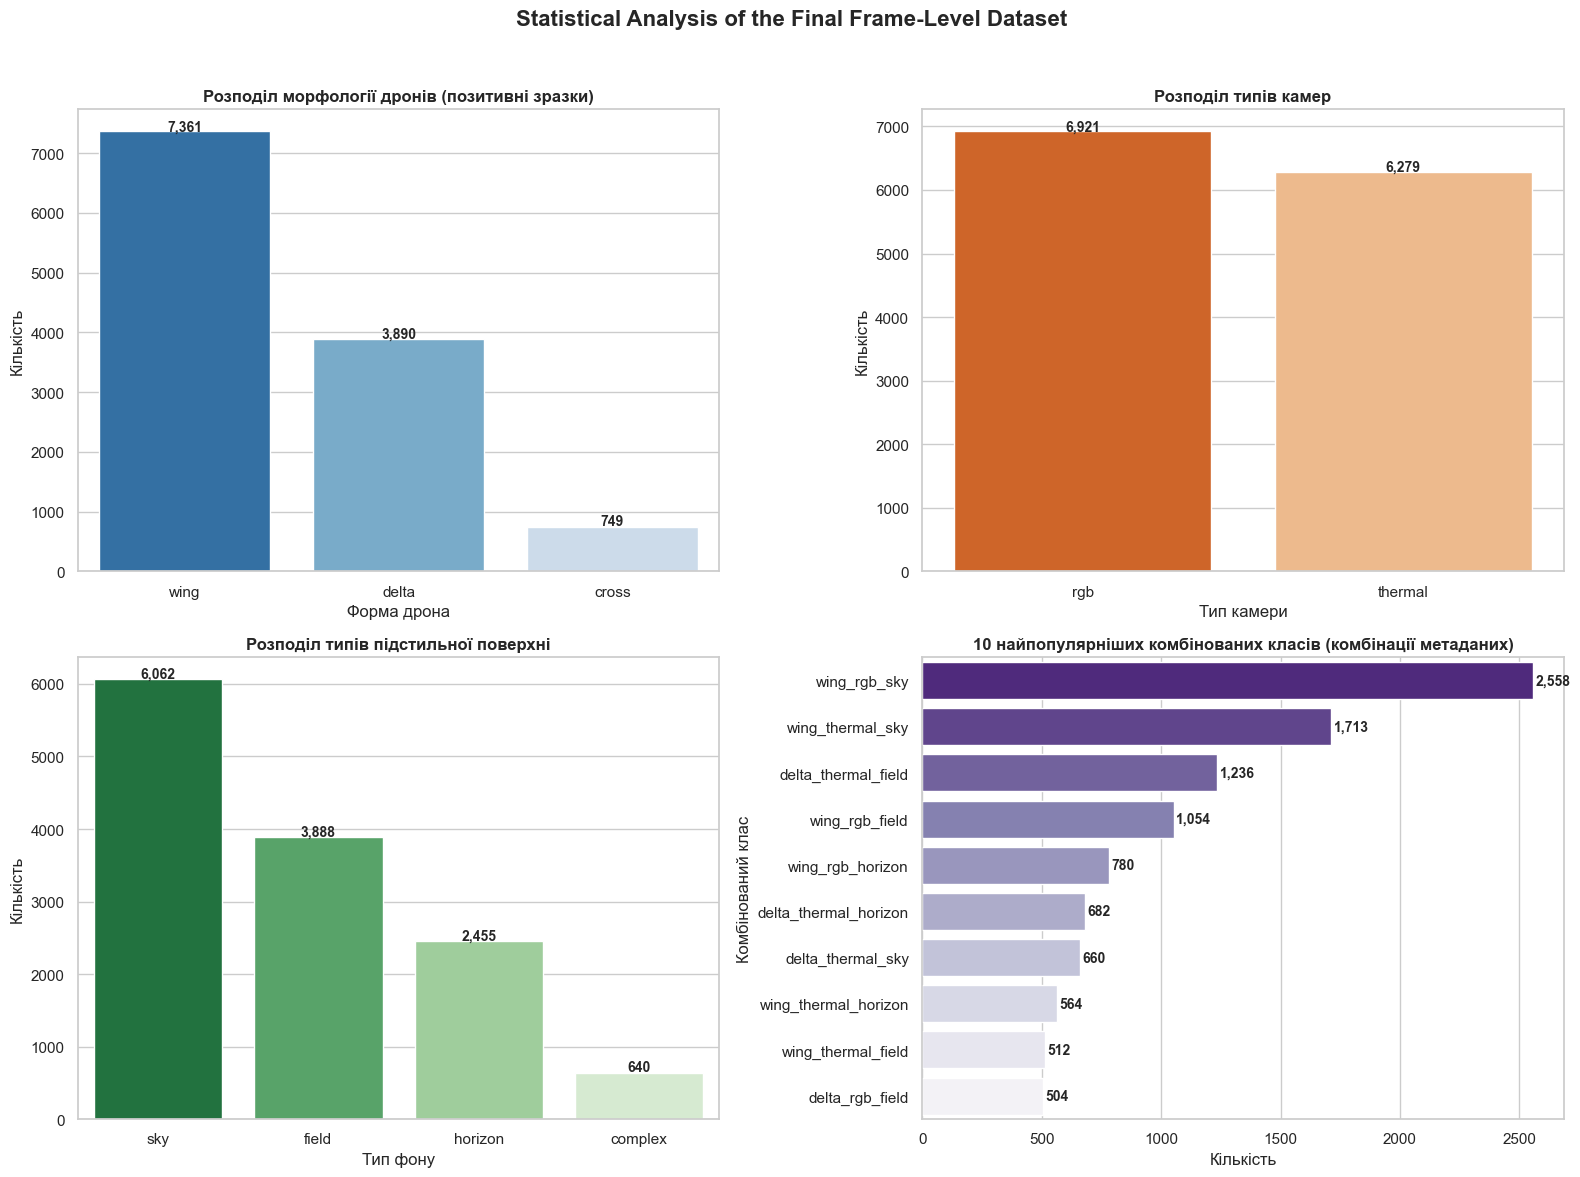


[+] Saved frame-level analysis report to: 'D:\anykn\python\bachelor\drone_classification\notebooks\model_analysis\final_dataset_frame_analysis.png'


In [10]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dotenv import load_dotenv



OUTPUT_DIR = Path("./model_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def parse_frame_filename(filename: str) -> dict:
    """
    Parses a flat frame filename to extract metadata.
    Template: [shape]_[camera]_[background]_[video_id]_f[frame_idx].jpg
    Safely handles negative files starting with 'no_drone' without index shifting.
    """
    # Replace 'no_drone' with 'nodrone' to prevent underscore index shifting
    clean_name = filename.replace("no_drone", "nodrone")
    parts = clean_name.split('_')
    
    if parts[0] == "nodrone":
        shape = "no_drone"
        camera = parts[1] if len(parts) > 1 else "unknown"
        # Check if parts[2] is a background name or a video ID digit
        if len(parts) > 2:
            if parts[2].isdigit():
                background = "unknown"
            else:
                background = parts[2]
        else:
            background = "unknown"
    else:
        shape = parts[0]
        camera = parts[1] if len(parts) > 1 else "unknown"
        background = parts[2] if len(parts) > 2 else "unknown"
        
    # Map 'forest' terrain class directly to 'complex' as requested
    if background == "forest":
        background = "complex"
        
    return {
        "shape": shape,
        "camera": camera,
        "background": background
    }


def run_dataset_frame_analysis():
    print(f"[*] Starting dataset frame-level metadata analysis...")
    print(f"    Scanning directory: {DATASET_DIR.resolve()}")
    
    splits = ["train", "val", "test"]
    data_records = []
    
    # Step 1: Scan positive and negative directories across splits
    for split in splits:
        pos_dir = DATASET_DIR / split / "RAW_POSITIVES"
        neg_dir = DATASET_DIR / split / "RAW_NEGATIVES"
        
        # Scan positive frames
        if pos_dir.exists():
            pos_images = list(pos_dir.glob("*.jpg"))
            for img_path in pos_images:
                meta = parse_frame_filename(img_path.name)
                data_records.append({
                    "filename": img_path.name,
                    "split": split,
                    "is_positive": True,
                    "shape": meta["shape"],
                    "camera": meta["camera"],
                    "background": meta["background"],
                    "combined_class": f"{meta['shape']}_{meta['camera']}_{meta['background']}"
                })
                
        # Scan negative frames
        if neg_dir.exists():
            neg_images = list(neg_dir.glob("*.jpg"))
            for img_path in neg_images:
                meta = parse_frame_filename(img_path.name)
                data_records.append({
                    "filename": img_path.name,
                    "split": split,
                    "is_positive": False,
                    "shape": "no_drone",  # Force shape category to 'no_drone' for negatives
                    "camera": meta["camera"],
                    "background": meta["background"],
                    "combined_class": f"no_drone_{meta['camera']}_{meta['background']}"
                })
                
    if not data_records:
        print(f"[!] Error: No image files found in {DATASET_DIR}")
        return

    # Convert gathered records to a Pandas DataFrame
    df = pd.DataFrame(data_records)
    print(f"[+] Successfully parsed metadata for {len(df):,} total frames.")

    # -----------------------------------------------------------------
    # PRINT DETAILED TEXT REPORT TO CONSOLE
    # -----------------------------------------------------------------
    total_frames = len(df)
    positives = df[df["is_positive"]]
    negatives = df[~df["is_positive"]]

    print("\n" + "="*60)
    print("         FINAL DATASET STATISTICAL REPORT (FRAMES)          ")
    print("============================================================")
    print(f"Total Extracted Frames  : {total_frames:,}")
    print(f"Positive Frames (Drones): {len(positives):,} ({len(positives)/total_frames*100:.1f}%)")
    print(f"Negative Frames (Empty) : {len(negatives):,} ({len(negatives)/total_frames*100:.1f}%)")
    print("-" * 60)
    print("SPLIT DISTRIBUTION:")
    for split in splits:
        split_df = df[df["split"] == split]
        split_pos = split_df[split_df["is_positive"]]
        split_neg = split_df[~split_df["is_positive"]]
        print(f"  * {split.upper():<5} Split: Total = {len(split_df):<5} | Positives = {len(split_pos):<5} | Negatives = {len(split_neg):<4}")
    
    print("-" * 60)
    print("DRONE MORPHOLOGY DISTRIBUTION (POSITIVES ONLY):")
    # Plot 1: Only active positive shapes (exclude no_drone from shape counts)
    shape_counts = positives[positives["shape"] != "no_drone"]["shape"].value_counts()
    
    # Plot 2: Camera Type (exclude fallback 'drone' and 'unknown' if any occur)
    camera_counts = df[~df["camera"].isin(["drone", "unknown"])]["camera"].value_counts()
    
    # Plot 3: Background Type (exclude 'rgb' and 'unknown' fallback values)
    bg_counts = df[~df["background"].isin(["rgb", "unknown"])]["background"].value_counts()
    
    # Plot 4: Top 10 Combined Classes
    combined_counts = df["combined_class"].value_counts().head(10)

    # -----------------------------------------------------------------
    # GENERATE 4-PANEL VISUAL DASHBOARD
    # -----------------------------------------------------------------
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle("Statistical Analysis of the Final Frame-Level Dataset", fontsize=16, fontweight="bold")

    # Plot 1: Drone Morphology (Shape) - Positives only
    sns.barplot(
        x=shape_counts.index, 
        y=shape_counts.values, 
        ax=axes[0, 0], 
        palette="Blues_r"
    )
    axes[0, 0].set_title("Розподіл морфології дронів (позитивні зразки)", fontsize=12, fontweight="bold")
    axes[0, 0].set_xlabel("Форма дрона")
    axes[0, 0].set_ylabel("Кількість")
    for i, v in enumerate(shape_counts.values):
        axes[0, 0].text(i, v + 20, f"{v:,}", ha="center", fontsize=10, fontweight="bold")

    # Plot 2: Camera Type (Sensor)
    sns.barplot(
        x=camera_counts.index, 
        y=camera_counts.values, 
        ax=axes[0, 1], 
        palette="Oranges_r"
    )
    axes[0, 1].set_title("Розподіл типів камер", fontsize=12, fontweight="bold")
    axes[0, 1].set_xlabel("Тип камери")
    axes[0, 1].set_ylabel("Кількість")
    for i, v in enumerate(camera_counts.values):
        axes[0, 1].text(i, v + 20, f"{v:,}", ha="center", fontsize=10, fontweight="bold")

    # Plot 3: Background Type (Tlo)
    sns.barplot(
        x=bg_counts.index, 
        y=bg_counts.values, 
        ax=axes[1, 0], 
        palette="Greens_r"
    )
    axes[1, 0].set_title("Розподіл типів підстильної поверхні", fontsize=12, fontweight="bold")
    axes[1, 0].set_xlabel("Тип фону")
    axes[1, 0].set_ylabel("Кількість")
    for i, v in enumerate(bg_counts.values):
        axes[1, 0].text(i, v + 20, f"{v:,}", ha="center", fontsize=10, fontweight="bold")

    # Plot 4: Top 10 Combined Classes
    combined_counts = df["combined_class"].value_counts().head(10)
    sns.barplot(
        x=combined_counts.values, 
        y=combined_counts.index, 
        ax=axes[1, 1], 
        palette="Purples_r"
    )
    axes[1, 1].set_title("10 найпопулярніших комбінованих класів (комбінації метаданих)", fontsize=12, fontweight="bold")
    axes[1, 1].set_xlabel("Кількість")
    axes[1, 1].set_ylabel("Комбінований клас")
    for i, v in enumerate(combined_counts.values):
        axes[1, 1].text(v + 10, i, f"{v:,}", va="center", fontsize=10, fontweight="bold")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    
    # Save the output plot
    output_plot_path = OUTPUT_DIR / "final_dataset_frame_analysis.png"
    plt.savefig(output_plot_path, dpi=300)
    plt.show()
    
    print(f"\n[+] Saved frame-level analysis report to: '{output_plot_path.resolve()}'")


if __name__ == "__main__":
    run_dataset_frame_analysis()

[*] Initializing target dimensions and size analysis...
    Scanning directory: E:\bachelor_data\extracted_dataset
[*] Found 12,000 positive label files. Commencing dimensions scan...


Parsing BBoxes: 100%|██████████| 12000/12000 [03:38<00:00, 54.82it/s] 



           TARGET SIZE METRICS REPORT               
Total Bounding Boxes Analyzed: 12,000
Mean Width  : 472.81 +/- 413.07 px
Mean Height : 150.09 +/- 144.38 px
Mean Area   : 114258.8 px^2
Mean Aspect Ratio (W/H)      : 3.861


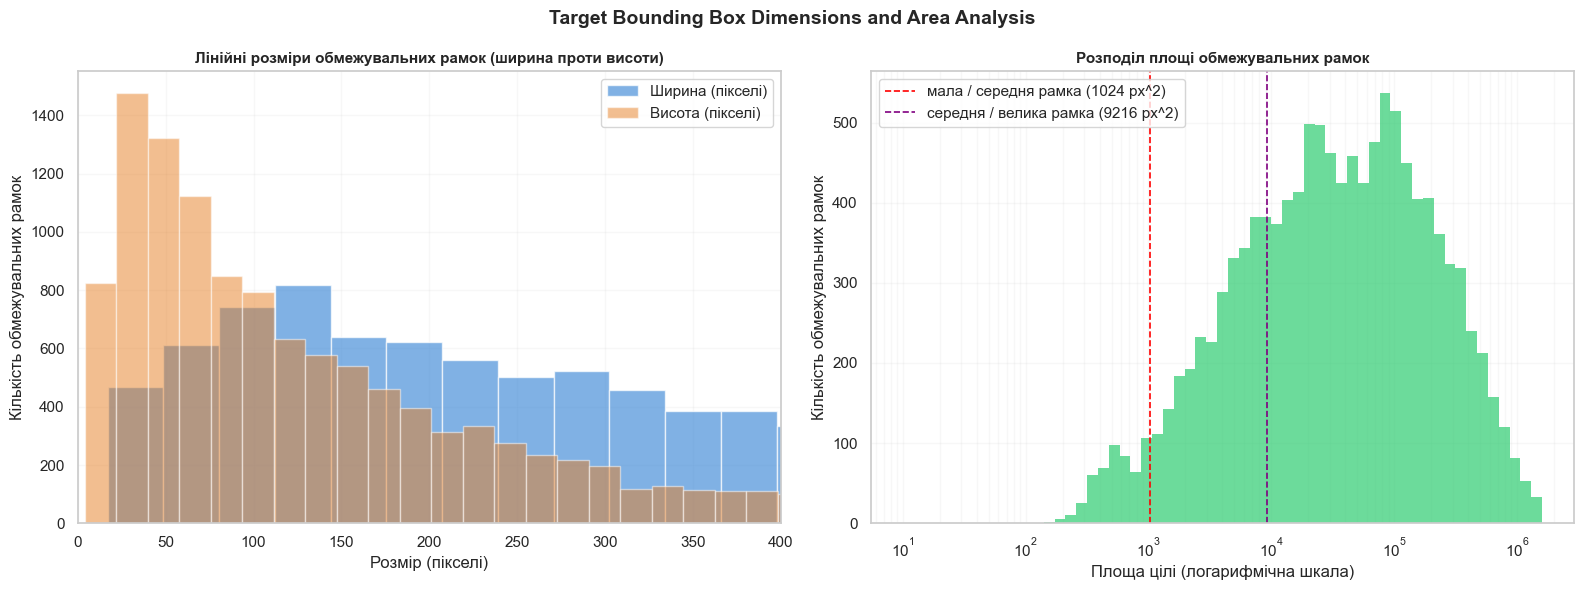


[+] Successfully generated target size analysis.
    Saved visual report to: 'D:\anykn\python\bachelor\drone_classification\notebooks\model_analysis\final_target_size_analysis.png'


In [13]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
from dotenv import load_dotenv

def run_target_size_analysis():
    print(f"[*] Initializing target dimensions and size analysis...")
    print(f"    Scanning directory: {DATASET_DIR.resolve()}")
    
    splits = ["train", "val", "test"]
    label_paths = []
    
    for split in splits:
        positives_dir = DATASET_DIR / split / "RAW_POSITIVES"
        if positives_dir.exists():
            label_paths.extend(list(positives_dir.glob("*.txt")))
            
    total_labels = len(label_paths)
    if total_labels == 0:
        print(f"[!] Error: No YOLO .txt label files found in: {DATASET_DIR}")
        return

    print(f"[*] Found {total_labels:,} positive label files. Commencing dimensions scan...")

    widths_px = []
    heights_px = []
    areas_px = []
    aspect_ratios = []
    total_boxes = 0

    for idx, path in enumerate(tqdm(label_paths, desc="Parsing BBoxes")):
        base_name = path.stem
        
        # Find corresponding image to get absolute pixel dimensions
        img_path = None
        for ext in [".jpg", ".png", ".jpeg"]:
            test_path = path.with_suffix(ext)
            if test_path.exists():
                img_path = test_path
                break
                
        if img_path is None:
            continue

        # Load image size safely without reading all pixels
        img = cv2.imread(str(img_path))
        if img is None:
            continue
            
        orig_h, orig_w = img.shape[:2]

        try:
            with open(path, "r") as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        # YOLO format: class_id x_center y_center width height (normalized)
                        w_norm = float(parts[3])
                        h_norm = float(parts[4])
                        
                        # Convert to absolute pixel dimensions
                        w_px = w_norm * orig_w
                        h_px = h_norm * orig_h
                        area_px = w_px * h_px
                        
                        widths_px.append(w_px)
                        heights_px.append(h_px)
                        areas_px.append(area_px)
                        aspect_ratios.append(w_px / h_px if h_px > 0 else 1.0)
                        total_boxes += 1
        except Exception as e:
            print(f"  [WARNING] Failed to parse file {path.name}: {e}")

    if total_boxes == 0:
        print("[!] Error: No valid bounding boxes were parsed.")
        return

    widths_px = np.array(widths_px)
    heights_px = np.array(heights_px)
    areas_px = np.array(areas_px)
    aspect_ratios = np.array(aspect_ratios)

    print("\n" + "="*50)
    print("           TARGET SIZE METRICS REPORT               ")
    print("====================================================")
    print(f"Total Bounding Boxes Analyzed: {total_boxes:,}")
    print(f"Mean Width  : {np.mean(widths_px):.2f} +/- {np.std(widths_px):.2f} px")
    print(f"Mean Height : {np.mean(heights_px):.2f} +/- {np.std(heights_px):.2f} px")
    print(f"Mean Area   : {np.mean(areas_px):.1f} px^2")
    print(f"Mean Aspect Ratio (W/H)      : {np.mean(aspect_ratios):.3f}")
    print("====================================================")

    # -----------------------------------------------------------------
    # GENERATE 2-PANEL ANALYSIS PLOT
    # -----------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Target Bounding Box Dimensions and Area Analysis", fontsize=14, fontweight="bold")

    # Plot 1: Overlay Histogram of Width and Height
    axes[0].hist(widths_px, bins=60, color="#4A90D9", alpha=0.7, label="Ширина (пікселі)")
    axes[0].hist(heights_px, bins=60, color="#E67E22", alpha=0.5, label="Висота (пікселі)")
    axes[0].set_title("Лінійні розміри обмежувальних рамок (ширина проти висоти)", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Розмір (пікселі)")
    axes[0].set_ylabel("Кількість обмежувальних рамок")
    axes[0].set_xlim(0, 400)  # Restrict to focus on the most dense area
    axes[0].legend()
    axes[0].grid(True, alpha=0.15)

    # Plot 2: Histogram of BBox Area on logarithmic scale
    # This highlights the standard COCO target size transitions at 1024 and 9216 px^2
    # We use logspace bins for smooth plotting over wide area scale range
    bins_log = np.logspace(np.log10(10), np.log10(1.6e6), 60)
    axes[1].hist(areas_px, bins=bins_log, color="#2ECC71", alpha=0.7, edgecolor="none")
    axes[1].set_xscale("log")
    
    # Draw COCO size boundary lines
    axes[1].axvline(1024, color="red", linestyle="--", linewidth=1.2, label="мала / середня рамка (1024 px^2)")
    axes[1].axvline(9216, color="purple", linestyle="--", linewidth=1.2, label="середня / велика рамка (9216 px^2)")
    
    axes[1].set_title("Розподіл площі обмежувальних рамок", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Площа цілі (логарифмічна шкала)")
    axes[1].set_ylabel("Кількість обмежувальних рамок")
    axes[1].legend()
    axes[1].grid(True, which="both", alpha=0.15)

    plt.tight_layout()
    
    # Save the output plot
    output_plot_path = OUTPUT_DIR / "final_target_size_analysis.png"
    plt.savefig(output_plot_path, dpi=300)
    plt.show()
    
    print(f"\n[+] Successfully generated target size analysis.")
    print(f"    Saved visual report to: '{output_plot_path.resolve()}'")


if __name__ == "__main__":
    run_target_size_analysis()

[*] Initializing local target-to-background contrast analysis...
    Scanning directory: E:\bachelor_data\extracted_dataset
[*] Found 12,000 positive label files. Starting pixel contrast profiling...


Profiling Contrast: 100%|██████████| 12000/12000 [04:30<00:00, 44.40it/s] 
C:\Users\anykn\AppData\Local\Temp\ipykernel_19960\1502074041.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(



         LOCAL CONTRAST STATISTICAL REPORT          
Camera: RGB
  Mean Contrast   : 0.2284 +/- 0.2965
  Median Contrast : 0.1628
--------------------------------------------------
Camera: THERMAL
  Mean Contrast   : 1.9299 +/- 7.8700
  Median Contrast : 0.2589
--------------------------------------------------


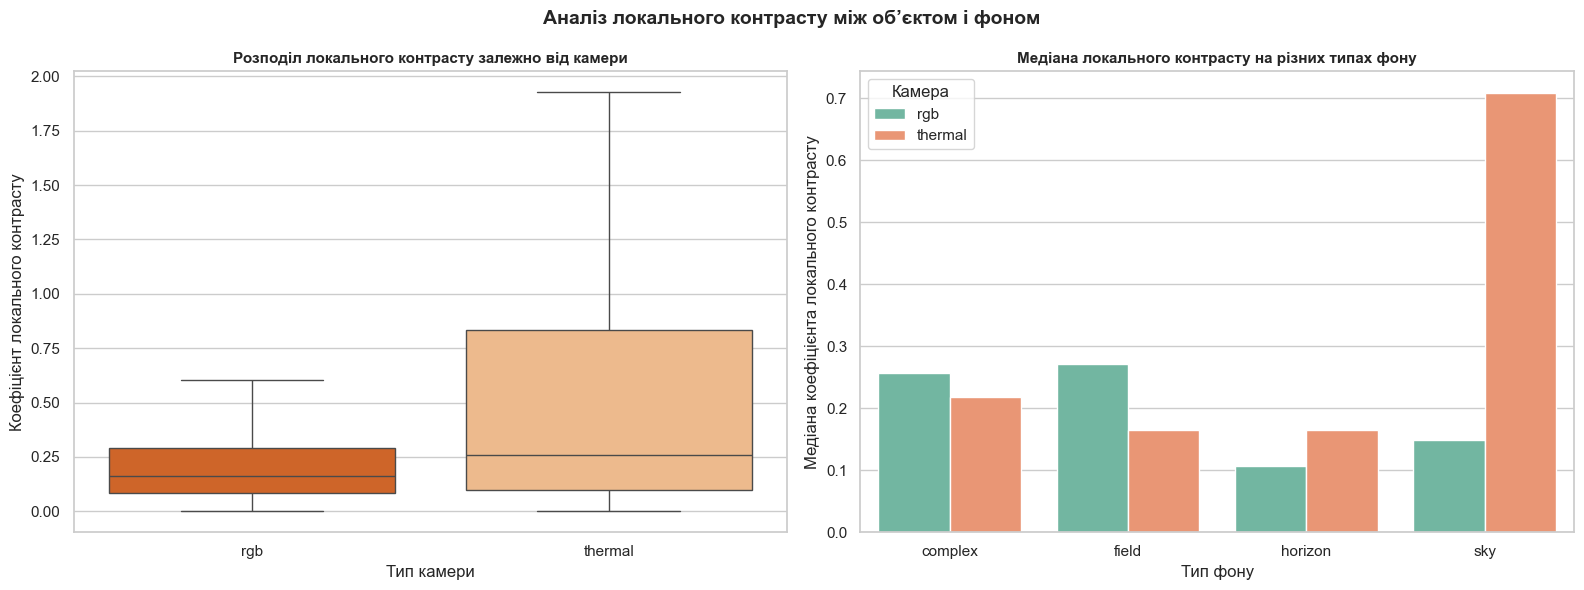


[+] Успішно згенеровано аналіз локального контрасту.
    Візуальний звіт збережено за адресою: 'D:\anykn\python\bachelor\drone_classification\notebooks\model_analysis\local_contrast_analysis.png'


In [17]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
from dotenv import load_dotenv


def parse_frame_filename(filename: str) -> dict:
    """Parses filename to extract metadata (handles no_drone correctly)."""
    clean_name = filename.replace("no_drone", "nodrone")
    parts = clean_name.split('_')
    
    if parts[0] == "nodrone":
        shape = "no_drone"
        camera = parts[1] if len(parts) > 1 else "unknown"
        if len(parts) > 2:
            background = "unknown" if parts[2].isdigit() else parts[2]
        else:
            background = "unknown"
    else:
        shape = parts[0]
        camera = parts[1] if len(parts) > 1 else "unknown"
        background = parts[2] if len(parts) > 2 else "unknown"
        
    if background == "forest":
        background = "complex"
        
    return {
        "shape": shape,
        "camera": camera,
        "background": background
    }


def run_contrast_analysis():
    print(f"[*] Initializing local target-to-background contrast analysis...")
    print(f"    Scanning directory: {DATASET_DIR.resolve()}")
    
    splits = ["train", "val", "test"]
    label_paths = []
    
    for split in splits:
        positives_dir = DATASET_DIR / split / "RAW_POSITIVES"
        if positives_dir.exists():
            label_paths.extend(list(positives_dir.glob("*.txt")))
            
    total_labels = len(label_paths)
    if total_labels == 0:
        print(f"[!] Error: No YOLO .txt label files found in: {DATASET_DIR}")
        return

    print(f"[*] Found {total_labels:,} positive label files. Starting pixel contrast profiling...")

    data = []

    for idx, path in enumerate(tqdm(label_paths, desc="Profiling Contrast")):
        base_name = path.stem
        meta = parse_frame_filename(path.name)
        
        # Skip unknown classes to keep the analysis clean
        if meta["camera"] == "unknown" or meta["background"] == "unknown":
            continue
            
        # Find corresponding image
        img_path = None
        for ext in [".jpg", ".png", ".jpeg"]:
            test_path = path.with_suffix(ext)
            if test_path.exists():
                img_path = test_path
                break
                
        if img_path is None:
            continue

        # Load image
        img = cv2.imread(str(img_path))
        if img is None:
            continue
            
        orig_h, orig_w = img.shape[:2]

        try:
            with open(path, "r") as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        w_norm = float(parts[3])
                        h_norm = float(parts[4])
                        x_c = float(parts[1])
                        y_c = float(parts[2])
                        
                        # Absolute target boundaries
                        x1 = int((x_c - w_norm/2.0) * orig_w)
                        y1 = int((y_c - h_norm/2.0) * orig_h)
                        x2 = int((x_c + w_norm/2.0) * orig_w)
                        y2 = int((y_c + h_norm/2.0) * orig_h)
                        
                        # Clip boundaries to image size
                        x1, y1 = max(0, x1), max(0, y1)
                        x2, y2 = min(orig_w - 1, x2), min(orig_h - 1, y2)
                        
                        w_box = x2 - x1
                        h_box = y2 - y1
                        
                        if w_box <= 0 or h_box <= 0:
                            continue
                            
                        # Define local background ring boundaries (expand by 50% on each side)
                        pad_w = int(w_box * 0.5)
                        pad_h = int(h_box * 0.5)
                        
                        bg_x1 = max(0, x1 - pad_w)
                        bg_y1 = max(0, y1 - pad_h)
                        bg_x2 = min(orig_w - 1, x2 + pad_w)
                        bg_y2 = min(orig_h - 1, y2 + pad_h)
                        
                        # Convert image slice to grayscale for luminance contrast calculations
                        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                        
                        # Target luminance mean
                        target_pixels = gray[y1:y2, x1:x2]
                        mean_target = np.mean(target_pixels)
                        
                        # Extract background mask excluding the target region
                        bg_mask = np.zeros_like(gray[bg_y1:bg_y2, bg_x1:bg_x2])
                        rel_x1 = x1 - bg_x1
                        rel_y1 = y1 - bg_y1
                        rel_x2 = x2 - bg_x1
                        rel_y2 = y2 - bg_y1
                        
                        bg_mask[:, :] = 255
                        bg_mask[rel_y1:rel_y2, rel_x1:rel_x2] = 0
                        
                        bg_pixels = gray[bg_y1:bg_y2, bg_x1:bg_x2][bg_mask == 255]
                        
                        if len(bg_pixels) > 0:
                            mean_bg = np.mean(bg_pixels)
                        else:
                            mean_bg = mean_target
                            
                        # Calculate Local Weber Contrast
                        contrast = abs(mean_target - mean_bg) / max(1.0, mean_bg)
                        
                        data.append({
                            "camera": meta["camera"],
                            "background": meta["background"],
                            "contrast": contrast
                        })
                        
        except Exception as e:
            print(f"  [WARNING] Failed to analyze file {path.name}: {e}")

    df = pd.DataFrame(data)
    if df.empty:
        print("[!] Error: No valid contract metrics were computed.")
        return

    # Print out summary statistics by camera type
    print("\n" + "="*50)
    print("         LOCAL CONTRAST STATISTICAL REPORT          ")
    print("====================================================")
    for cam in df["camera"].unique():
        cam_df = df[df["camera"] == cam]
        print(f"Camera: {cam.upper()}")
        print(f"  Mean Contrast   : {np.mean(cam_df['contrast']):.4f} +/- {np.std(cam_df['contrast']):.4f}")
        print(f"  Median Contrast : {np.median(cam_df['contrast']):.4f}")
        print("-" * 50)
    print("====================================================")

# -----------------------------------------------------------------
    # GENERATE 2-PANEL ANALYSIS PLOT (Optimized with Median estimator)
    # -----------------------------------------------------------------
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Аналіз локального контрасту між об’єктом і фоном", fontsize=14, fontweight="bold")

    # Plot 1: Boxplot of Contrast by Camera Type
    sns.boxplot(
        x="camera", 
        y="contrast", 
        data=df, 
        ax=axes[0], 
        palette="Oranges_r",
        showfliers=False  # Hide extreme outliers for visualization clarity
    )
    axes[0].set_title("Розподіл локального контрасту залежно від камери", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Тип камери")
    axes[0].set_ylabel("Коефіцієнт локального контрасту")

    # Plot 2: Barplot of MEDIAN Contrast across Backgrounds (grouped by Camera)
    df_clean = df[~df["background"].isin(["rgb", "unknown"])]
    sns.barplot(
        x="background", 
        y="contrast", 
        hue="camera", 
        data=df_clean, 
        ax=axes[1], 
        palette="Set2",
        estimator=np.median,  # CHANGED: Use median instead of mean to align with Boxplot
        errorbar=None         # Remove error bars for cleaner look
    )
    axes[1].set_title("Медіана локального контрасту на різних типах фону", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Тип фону")
    axes[1].set_ylabel("Медіана коефіцієнта локального контрасту")
    axes[1].legend(title="Камера")

    plt.tight_layout()
    
    # Save the output plot
    output_plot_path = OUTPUT_DIR / "local_contrast_analysis.png"
    plt.savefig(output_plot_path, dpi=300)
    plt.show()
    
    print(f"\n[+] Успішно згенеровано аналіз локального контрасту.")
    print(f"    Візуальний звіт збережено за адресою: '{output_plot_path.resolve()}'")


if __name__ == "__main__":
    run_contrast_analysis()